# Section 3.1: RIDDLE on five simulated corpora

**RIDDLE** is the GNN (`ours/l2mix_pair/selF1`; relaxed L2, relaxed L3 on the L-3 corpus) followed by the MAP
re-choice of its low-z clusters (z < 6) among their NNI alternatives, scored by `z+tc`, under the **train-fit
β**. That β was fitted on the GNN's own training networks, selected on its validation networks, and transferred
unchanged to every corpus here (`nni_ensemble/README.md`, "Train-fit calibration"). The tables call it
`GNN MAP [z+tc]`; this notebook calls it RIDDLE everywhere. The emitted GNN is not drawn.

**Compared methods**
- **BROOQS** and **NetCS** resolve a tree of blobs (TOB).
- **CAMUS**, on the CAMUS corpus only: its own pre-inferred networks, `camus_f05` built from the FastTree gene
  trees of the `cam_g500` arm. CAMUS emits a ladder with one network per reticulation count. The rung drawn is
  k = k_true, because RIDDLE's decode is handed k_true as its reticulation budget.

**Metrics**
- cluster F1 (higher is better);
- normalised Nakhleh distance, `luay_norm_exact` from PhyloNet `CMPNETS -m luay` (lower is better);
- balanced hybrid-ancestry error, HAE (lower is better).

| corpus | cells | taxa | design axes | reticulations k |
|---|---|---|---|---|
| CAMUS | 80 | 50, 100, 150, 200 | n (level-1 throughout) | 1–6 |
| Regular L-2 | 20 | 200 | ILS: mean internal branch 0.25 / 0.5 CU | 3–9 |
| Regular L-3 | 20 | 200 | ILS: 0.25 / 0.5 CU | 4–12 |
| N=1000 | 20 | 1000 | ILS: 0.25 / 0.5 CU; 10,000 estimated gene trees; resolvers on the GNN's TOB | 3–9 |
| NetCS | 1,200 | 50, 100, 200 | level 1 / 2 × ILS scale 0.25 / 0.5 / 1 / 2 | 1–5 |

The published benches lack 18 headline cells: L-2 rep07 and 17 NetCS cells, which a faulty gate fixture
kept out (`plotting_ztc_bench.ipynb`, section 0). The **fill** benches score exactly those cells, with the same
β and the same landed resolver rows, and accuracy here reads them. So every corpus is complete: 80 / 20 / 20 /
20 / 1,200 cells. Runtime has no fill rows, so the runtime figures use 19 L-2 and 1,183 NetCS cells. On both ILS
axes **0.25 is the most ILS**.

**Inputs** (this notebook only reads and draws)

| table | built by |
|---|---|
| `nni_ensemble/results/trainfit/<corpus>_bench.csv` | `nni_ensemble/bench.py` under the train-fit β (`run_trainfit.sh`) |
| `nni_ensemble/results/trainfit/derived/{l2reg,netcs}_fill_bench.csv` | `bench.py --out-stem fill` under the train-fit β: the 18 cells the published benches lack |
| `subsample_eval/results/camus_sub500_res.csv` (full draw) | `make_res_csv.py`: the resolver status the camus landed file does not carry |
| `nni_ensemble/results/camus_own_bench.csv` | `nni_ensemble/camus_own.py`: CAMUS's ladder at k = k_true, HAE scored by `bench.score_ha` |
| `nni_ensemble/results/<corpus>_runtime.csv` | `nni_ensemble/runtime.py` (β-free: the MAP's computation does not depend on β) |
| `<corpus>_eval/CELLS.tsv`, `gnn_cpu_v1/CELLS.tsv` | the true reticulation count k of each cell |

Kernel: `phylo-env`. Figures go to `plots/` as `AllDatasets-sec3-1-<figure>-ours_l2mix_pair_selF1.png`. Every
figure cell sets its own sizes and fonts at the top.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import wilcoxon

# RIDDLE = GNN MAP [z+tc] under the train-fit beta.  The runtime tables and CAMUS's own networks do not depend
# on beta, so they are read from the published directory.
BENCH_DIR = Path("data/results/trainfit")
PUB_DIR = Path("data/results")
FIG_DIR = Path("../plots")
TAG = "ours_l2mix_pair_selF1"

CORPORA = ["camus", "l2reg", "l3reg", "n1000", "netcs"]          # figure rows, top to bottom
CORPUS_TITLE = {"camus": "CAMUS corpus", "l2reg": "Regular L-2 corpus", "l3reg": "Regular L-3 corpus",
                "n1000": "1,000-taxon corpus", "netcs": "NetCS corpus"}
CORPUS_SHORT = {"camus": "CAMUS-data", "l2reg": "Regular L-2", "l3reg": "Regular L-3", "n1000": "N=1,000",
                "netcs": "NetCS-data"}
CELLS_TSV = {"camus": "../gnn_cpu_v1/CELLS.tsv", "l2reg": "../l2reg_eval/CELLS.tsv",
             "l3reg": "../l3reg_eval/CELLS.tsv", "n1000": "../n1000_eval/CELLS.tsv",
             "netcs": "../netcs_eval/CELLS.tsv"}

RENAME = {"GNN MAP [z+tc]": "RIDDLE", "BROOQS": "BROOQS", "NetCS": "NetCS", "CAMUS": "CAMUS"}
METHODS = ["RIDDLE", "BROOQS", "NetCS", "CAMUS"]
# The dataviz reference palette's slots 1, 3, 4, 5, in this order.  validate_palette.js passes it: worst
# adjacent CVD dE 9.1, normal-vision dE 19.6.  Aqua, yellow and magenta are under 3:1 on white, so every
# mark gets a dark edge, every figure a legend, and every figure a table after it.
COLOR = {"RIDDLE": "#2a78d6", "BROOQS": "#1baf7a", "NetCS": "#eda100", "CAMUS": "#e87ba4"}
MARKER = {"RIDDLE": "o", "BROOQS": "^", "NetCS": "D", "CAMUS": "s"}
METRICS = [("cluster_f1", "Cluster F1", "higher"),
           ("luay_norm_exact", "Norm. top. distance", "lower"),
           ("ha_balanced_error", "Balanced HAE", "lower")]
EDGE, INK, MUTED, GRID = "#333333", "#52514e", "#898781", "#e6e5e0"
RNG = np.random.default_rng(20261022)
N_BOOT = 1000
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
                     "hatch.linewidth": 0.7, "savefig.dpi": 300})
FIG_DIR.mkdir(exist_ok=True)

In [2]:
# Accuracy: one row per (headline cell, method).  RIDDLE, BROOQS and NetCS come from the train-fit bench;
# CAMUS's own networks from camus_own.py.  Every gate file must be clean.
for name in ["bench_trainfit_gates.json", "bench_n1000_gates.json", "derived/bench_fill_gates.json"]:
    g = json.loads((BENCH_DIR / name).read_text())
    assert g["variant"] == "z+tc" and not g["problems"], (name, g["variant"], g["problems"][:5])
g = json.loads((PUB_DIR / "camus_own_gates.json").read_text())
assert not g["problems"] and g["stats"]["rung"] == "k_true", g["problems"][:5]

frames = []
for ds in CORPORA:
    b = pd.read_csv(BENCH_DIR / f"{ds}_bench.csv")
    frames.append(b[b.method.isin(["GNN MAP [z+tc]", "BROOQS", "NetCS"])])
# The fill: the 18 headline cells the published benches lack (L-2 rep07, 17 NetCS cells), benched under the same
# beta from the same landed resolver rows.  Its `dataset` is the fill's name; the corpus is its base.
for ds in ["l2reg", "netcs"]:
    b = pd.read_csv(BENCH_DIR / "derived" / f"{ds}_fill_bench.csv").assign(dataset=ds)
    assert not set(b.cell) & set(frames[CORPORA.index(ds)].cell), f"{ds}: a fill cell is already published"
    frames.append(b[b.method.isin(["GNN MAP [z+tc]", "BROOQS", "NetCS"])])
own = pd.read_csv(PUB_DIR / "camus_own_bench.csv")
frames.append(own.drop(columns=["k_true", "k_pred", "source"]))
ACC = pd.concat(frames, ignore_index=True).rename(columns={"dataset": "corpus"})
ACC["method"] = ACC.method.map(RENAME)
assert ACC.method.notna().all()
ACC["status"] = ACC.status.fillna("ok")

# The camus landed file has no status column, so a NetCS network with OUT below one of its own hybrids reads as
# "ok" there, with no Nakhleh distance.  subsample_eval's full-data resolver rows carry the status; take it where
# their cluster F1 equals the bench's (bench.py's join rule).
res = pd.read_csv("../subsample_eval/results/camus_sub500_res.csv")
res = res[(res.draw == "full") & (res.variant == "raw") & (res.protocol == "rooted")]
res = res[["phase", "rep", "arm", "method", "status", "cluster_f1"]].rename(
    columns={"status": "res_status", "cluster_f1": "res_f1"})
ACC = ACC.merge(res, on=["phase", "rep", "arm", "method"], how="left", validate="many_to_one")
agree = ACC.res_status.notna() & np.isclose(ACC.cluster_f1, ACC.res_f1, atol=1e-6)
assert (agree == ACC.res_status.notna()).all(), "a camus resolver row disagrees with subsample_eval on F1"
ACC.loc[agree, "status"] = ACC.loc[agree, "res_status"]
ACC = ACC.drop(columns=["res_status", "res_f1"])

# the true reticulation count k of every cell, from its corpus's CELLS.tsv
K = pd.concat([pd.read_csv(p, sep="\t")[["phase", "rep", "arm", "k"]] for p in CELLS_TSV.values()])
ACC = ACC.merge(K, on=["phase", "rep", "arm"], how="left", validate="many_to_one")
assert ACC.k.notna().all()
chk = own.merge(K, on=["phase", "rep", "arm"])
assert len(chk) == len(own) and (chk.k_true == chk.k).all(), "CAMUS's rung is not k_true"

# the nominal taxon count: NetCS's `n` counts the taxa actually present (101, 202, ...), its phase the nominal n
ACC["n_nom"] = [1000 if c == "n1000" else int(re.search(r"(\d+)$", p).group(1))
                for c, p in zip(ACC.corpus, ACC.phase)]
assert not ACC.duplicated(["corpus", "cell", "method"]).any()
ACC.groupby(["corpus", "method"]).cell.nunique().unstack().reindex(index=CORPORA, columns=METHODS)

method,RIDDLE,BROOQS,NetCS,CAMUS
corpus,,,,
camus,80.0,80.0,80.0,80.0
l2reg,20.0,20.0,20.0,NaN
l3reg,20.0,20.0,20.0,NaN
n1000,20.0,20.0,20.0,NaN
netcs,1200.0,1200.0,1200.0,NaN


In [3]:
# Runtime: seconds per (cell, method).  CLOCK picks the clock.  "wall" is the only one with a TOB time on the
# L-2 / L-3 corpora (TREE-QMC's self-reported wall).  CPU and wall agree to about 1% for every method here, since
# each is single-threaded, so the choice moves no box visibly.
CLOCK = "wall"
frames = []
for ds in CORPORA:
    g = json.loads((PUB_DIR / f"{ds}_runtime_gates.json").read_text())
    assert not g["problems"], (ds, g["problems"][:5])
    r = pd.read_csv(PUB_DIR / f"{ds}_runtime.csv")
    frames.append(r[r.method.isin(["GNN MAP [z+tc]", "BROOQS", "NetCS"])])
RT = pd.concat(frames, ignore_index=True).rename(columns={"dataset": "corpus"})
RT["method"] = RT.method.map(RENAME)
RT["n_nom"] = [1000 if c == "n1000" else int(re.search(r"(\d+)$", p).group(1))
               for c, p in zip(RT.corpus, RT.phase)]

# Resolver only: the method's own time.  For RIDDLE that is the whole method, from gene trees to network
# (GNN + add-on + amortised calibration).
RT["resolver_s"] = RT[f"method_{CLOCK}_s"]
# Resolver + TOB inference is drawn only where the TOB was inferred and timed (TREE-QMC --blob on CAMUS, L-2,
# L-3).  NetCS ships its TOB, and on N=1000 the TOB is the GNN's own network, so both stay resolver-only.
RT["with_tob_s"] = RT[f"e2e_{CLOCK}_s"].where(RT.method.ne("RIDDLE") & RT.corpus.ne("n1000"))
has = RT.with_tob_s.notna()
# runtime.py's R5: end to end = TOB + resolver (to the tables' 6 printed digits)
assert np.allclose(RT.loc[has, "with_tob_s"], RT.loc[has, f"tob_{CLOCK}_s"] + RT.loc[has, "resolver_s"], rtol=1e-5)
# runtime.py times the published cells only, so the 18 fill cells have no runtime rows (19 L-2, 1,183 NetCS here)
assert set(RT.cell) <= set(ACC.cell) and len(set(ACC.cell) - set(RT.cell)) == 18
RT.groupby(["corpus", "method"])[["resolver_s", "with_tob_s"]].count().unstack().reindex(CORPORA)

resolver_s              with_tob_s             
method     BROOQS NetCS RIDDLE     BROOQS NetCS RIDDLE
corpus                                                
camus          80    80     80         80    80      0
l2reg          19    19     19         19    19      0
l3reg          20    20     20         20    20      0
n1000          20    20     20          0     0      0
netcs        1183  1183   1183          0     0      0

In [4]:
# Coverage: what every box below is drawn from.  A count below `cells` has one of three causes, each counted here:
#   failed            -- the resolver crashed or its output could not be scored (`status` starts "error"): no metric;
#   OUT below hybrid  -- the output puts the outgroup below one of its own hybrids, so it has no OUT-rooted
#                        reading: F1 and HAE are read as emitted, and there is no Nakhleh distance (the landed rule);
#   no retic.         -- the output has no reticulation, so HAE has no false-positive rate and no balanced error.
cov = (ACC.groupby(["corpus", "method"])
          .agg(cells=("cell", "nunique"), **{lab: (col, "count") for col, lab, _ in METRICS},
               failed=("status", lambda s: int(s.str.startswith("error").sum())),
               out_below=("status", lambda s: int((s == "out_not_rootable").sum())))
          .rename(columns={"out_below": "OUT below hybrid"}))
cov["no retic."] = (ACC[(ACC.status == "ok") | (ACC.status == "out_not_rootable")]
                    .assign(x=lambda d: d.ha_fpr.isna() & d.ha_fnr.notna())
                    .groupby(["corpus", "method"]).x.sum().astype(int))
# every missing value is accounted for by exactly those causes
F1, NAK, HAE = (lab for _, lab, _ in METRICS)
assert (cov.cells - cov[F1] == cov.failed).all()
assert (cov.cells - cov[NAK] == cov.failed + cov["OUT below hybrid"]).all()
assert (cov.cells - cov[HAE] == cov.failed + cov["no retic."]).all()
cov.reindex([(c, m) for c in CORPORA for m in METHODS if (c, m) in cov.index])

cells  Cluster F1  Norm. top. distance  Balanced HAE  failed  \
corpus method                                                                 
camus  RIDDLE     80          80                   80            80       0   
       BROOQS     80          80                   80            77       0   
       NetCS      80          80                   65            76       0   
       CAMUS      80          80                   80            80       0   
l2reg  RIDDLE     20          20                   20            20       0   
       BROOQS     20          20                   20            20       0   
       NetCS      20          20                   19            20       0   
l3reg  RIDDLE     20          20                   20            20       0   
       BROOQS     20          20                   20            20       0   
       NetCS      20          19                   14            19       1   
n1000  RIDDLE     20          20                   20            20       0   
       BROOQS     20          20                   20            20       0   
       NetCS      20          20                   13            20       0   
netcs  RIDDLE   1200        1200                 1200          1200       0   
       BROOQS   1200        1197                 1197          1182       3   
       NetCS    1200        1188                 1188          1138      12   

               OUT below hybrid  no retic.  
corpus method                               
camus  RIDDLE                 0          0  
       BROOQS                 0          3  
       NetCS                 15          4  
       CAMUS                  0          0  
l2reg  RIDDLE                 0          0  
       BROOQS                 0          0  
       NetCS                  1          0  
l3reg  RIDDLE                 0          0  
       BROOQS                 0          0  
       NetCS                  5          0  
n1000  RIDDLE                 0          0  
       BROOQS                 0          0  
       NetCS                  7          0  
netcs  RIDDLE                 0          0  
       BROOQS                 0         15  
       NetCS                  0         50

## Main Figure 1: accuracy across the five corpora

Rows are corpora and columns are metrics. Colour identifies the method.
- **Boxes** show the median and quartiles, with whiskers at 1.5 IQR.
- The **white diamond** is the mean.
- **Grey points** are cells; above 100 cells only the fliers are drawn.
- An `n=` under a box means it has fewer values than the corpus has cells (see the coverage table).

CAMUS appears on the CAMUS row only. The y axis is [0, 1] on every panel.

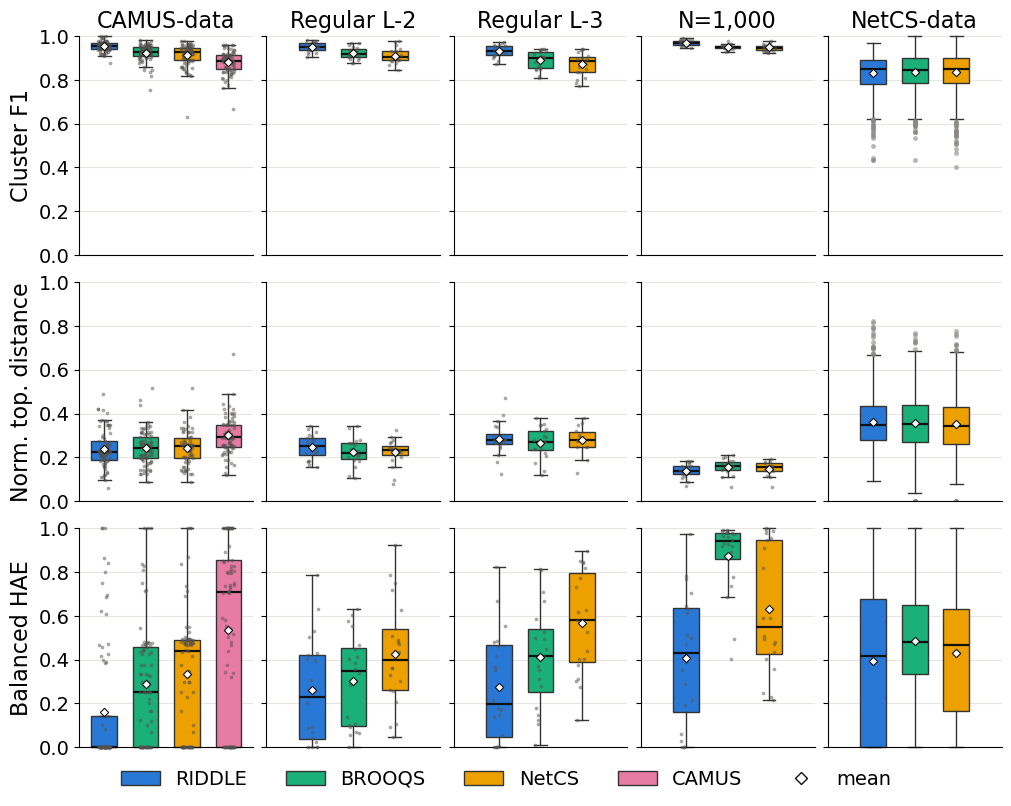

In [5]:
FIGSIZE = (10, 8)
TITLE_FS, LABEL_FS, TICK_FS, LEGEND_FS, N_FS = 16, 16, 14, 14, 9
YLIM = (0, 1)
BOX_W = 0.62
POINTS_MAX = 100        # every cell is drawn as a point up to this many; fliers only above it
SHOW_N = False          # "n=" under a box with fewer values than the corpus has cells

n_slots = len(METHODS)
fig, axes = plt.subplots(len(METRICS), len(CORPORA), figsize=FIGSIZE, sharey=True, squeeze=True,
                         layout="constrained")
for j, ds in enumerate(CORPORA):
    A = ACC[ACC.corpus == ds]
    methods = [m for m in METHODS if (A.method == m).any()]
    offset = (n_slots - len(methods)) / 2          # centre a column's boxes when it has fewer methods
    n_cells = A.cell.nunique()
    for i, (col, lab, better) in enumerate(METRICS):
        ax = axes[i, j]
        ticks, ticklabels = [], []
        for s, m in enumerate(methods):
            pos = s + 1 + offset
            v = A.loc[A.method == m, col].dropna().to_numpy()
            ticks.append(pos)
            ticklabels.append(f"n={len(v)}" if SHOW_N and len(v) < n_cells else "")
            if len(v) == 0:
                continue
            few = len(v) <= POINTS_MAX
            bp = ax.boxplot([v], positions=[pos], widths=BOX_W, patch_artist=True, showfliers=not few,
                            medianprops=dict(color="#111111", lw=1.6),
                            whiskerprops=dict(color=EDGE, lw=1), capprops=dict(color=EDGE, lw=1),
                            flierprops=dict(marker=".", ms=7, mfc=MUTED, mec="none", alpha=0.6))
            bp["boxes"][0].set(facecolor=COLOR[m], edgecolor=EDGE, linewidth=1)
            # a value of exactly 0 or 1 sits on the frame, not under it.  Never the fliers: an empty, unclipped
            # flier line has its bounding box at the figure's origin and wrecks the layout.
            for artist in bp["boxes"] + bp["whiskers"] + bp["caps"] + bp["medians"]:
                artist.set_clip_on(False)
            if few:
                ax.scatter(pos + RNG.uniform(-0.15, 0.15, len(v)), v, s=7, color=INK, alpha=0.5, lw=0,
                           zorder=3, clip_on=False)
            ax.scatter([pos], [v.mean()], marker="D", s=18, color="white", edgecolor="#111111", lw=0.8,
                       zorder=4, clip_on=False)
        ax.set_xlim(0.4, n_slots + 0.6)
        ax.set_xticks(ticks)
        ax.set_xticklabels(ticklabels, fontsize=N_FS, color=INK)
        ax.tick_params(axis="x", length=0)
        ax.set_ylim(*YLIM)
        ax.tick_params(axis="y", labelsize=TICK_FS)
        ax.grid(axis="y", color=GRID, lw=0.8)
        if i == 0:
            ax.set_title(CORPUS_SHORT[ds], fontsize=TITLE_FS)
        if j == 0:
            ax.set_ylabel(lab, fontsize=LABEL_FS)

handles = [Patch(facecolor=COLOR[m], edgecolor=EDGE, label=m) for m in METHODS]
handles.append(Line2D([], [], marker="D", ls="", color="white", markeredgecolor="#111111", markersize=6, label="mean"))
fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), fontsize=LEGEND_FS, frameon=False)
fig.savefig(FIG_DIR / f"AllDatasets-sec3-1-accuracy-{TAG}.png", bbox_inches="tight", dpi=300)
plt.show()

In [6]:
# The numbers behind Figure 1: median and mean per corpus, method and metric.
rows = []
for ds in CORPORA:
    A = ACC[ACC.corpus == ds]
    for m in METHODS:
        S = A[A.method == m]
        if S.empty:
            continue
        row = {"corpus": CORPUS_SHORT[ds], "method": m, "cells": S.cell.nunique()}
        for col, lab, _ in METRICS:
            row[f"{lab} median"] = S[col].median()
            row[f"{lab} mean"] = S[col].mean()
        rows.append(row)
pd.DataFrame(rows).set_index(["corpus", "method"]).round(4)

cells  Cluster F1 median  Cluster F1 mean  \
corpus      method                                              
CAMUS-data  RIDDLE     80             0.9571           0.9543   
            BROOQS     80             0.9296           0.9249   
            NetCS      80             0.9266           0.9128   
            CAMUS      80             0.8889           0.8808   
Regular L-2 RIDDLE     20             0.9498           0.9509   
            BROOQS     20             0.9201           0.9227   
            NetCS      20             0.9046           0.9117   
Regular L-3 RIDDLE     20             0.9327           0.9323   
            BROOQS     20             0.9004           0.8893   
            NetCS      20             0.8878           0.8711   
N=1,000     RIDDLE     20             0.9711           0.9707   
            BROOQS     20             0.9521           0.9513   
            NetCS      20             0.9476           0.9485   
NetCS-data  RIDDLE   1200             0.8485           0.8306   
            BROOQS   1200             0.8462           0.8363   
            NetCS    1200             0.8513           0.8371   

                    Norm. top. distance median  Norm. top. distance mean  \
corpus      method                                                         
CAMUS-data  RIDDLE                      0.2236                    0.2399   
            BROOQS                      0.2404                    0.2444   
            NetCS                       0.2516                    0.2442   
            CAMUS                       0.2915                    0.3005   
Regular L-2 RIDDLE                      0.2518                    0.2483   
            BROOQS                      0.2205                    0.2242   
            NetCS                       0.2350                    0.2236   
Regular L-3 RIDDLE                      0.2791                    0.2848   
            BROOQS                      0.2719                    0.2665   
            NetCS                       0.2782                    0.2775   
N=1,000     RIDDLE                      0.1367                    0.1393   
            BROOQS                      0.1605                    0.1573   
            NetCS                       0.1566                    0.1477   
NetCS-data  RIDDLE                      0.3500                    0.3613   
            BROOQS                      0.3524                    0.3590   
            NetCS                       0.3451                    0.3523   

                    Balanced HAE median  Balanced HAE mean  
corpus      method                                          
CAMUS-data  RIDDLE               0.0000             0.1594  
            BROOQS               0.2500             0.2892  
            NetCS                0.4410             0.3349  
            CAMUS                0.7076             0.5340  
Regular L-2 RIDDLE               0.2308             0.2596  
            BROOQS               0.3493             0.3044  
            NetCS                0.3988             0.4256  
Regular L-3 RIDDLE               0.1962             0.2761  
            BROOQS               0.4183             0.4135  
            NetCS                0.5825             0.5663  
N=1,000     RIDDLE               0.4308             0.4068  
            BROOQS               0.9405             0.8729  
            NetCS                0.5484             0.6307  
NetCS-data  RIDDLE               0.4167             0.3942  
            BROOQS               0.4821             0.4839  
            NetCS                0.4692             0.4327

## Main Figure 2: runtime scaling

The y axis is seconds per network on a log scale; the x axis is the number of taxa. At each n, **every corpus
with that n is pooled**:
- 50 and 100: CAMUS and NetCS;
- 150: CAMUS;
- 200: CAMUS, L-2, L-3 and NetCS;
- 1000: N=1000.

S4 below unpools them.

**Encoding**
- Colour is the method.
- **Solid** is the resolver alone. For RIDDLE that is the whole method, from gene trees to network: GNN, add-on
  and amortised calibration.
- **Hatched and lighter** is the resolver plus TOB inference (TREE-QMC `--blob`). It is drawn on the cells where
  that TOB was inferred and timed: CAMUS at every n, and L-2 and L-3 at 200. NetCS ships its TOB.
- **On N=1000 the TOB is the GNN's own network**, so BROOQS and NetCS are drawn resolver-only there.
- Boxes show the median and quartiles, with whiskers at the 5th–95th percentiles. The white diamond is the
  mean. Tick labels give the cells pooled at that n, and how many of them have a TOB time.

**Cells.** The fill cells (L-2 rep07 and 17 NetCS cells) have no runtime rows, so this figure uses 19 L-2 and
1,183 NetCS cells.

**Clock and hosts.** Wall time (`CLOCK`, in the loading cell). Every source ran several cells at once, so wall
time is taken under load.

| what | where |
|---|---|
| RIDDLE | Mac (`C4537CLFY0`), one thread per invocation; up to 5 at once on NetCS, 4 on N=1000 |
| BROOQS, NetCS, n ≤ 200 | Mac, 8 at a time (12 on NetCS) |
| BROOQS, NetCS, N=1000 | Linux (kimura) |
| TOB, CAMUS | TREE-QMC on the Mac (the `blob_cpu_v1` re-run) |
| TOB, L-2 / L-3 | TREE-QMC's self-reported wall time on the Linux box |

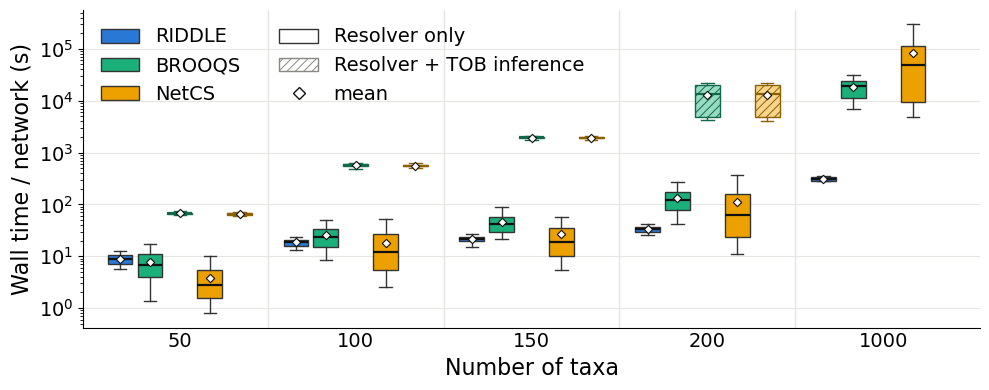

In [7]:
FIGSIZE = (10, 4)
LABEL_FS, TICK_FS, LEGEND_FS, NOTE_FS = 16, 14, 14, 9
N_ORDER = [50, 100, 150, 200, 1000]
# (method, column, hatched): the five slots at each taxon count, left to right
SLOTS = [("RIDDLE", "resolver_s", False),
         ("BROOQS", "resolver_s", False), ("BROOQS", "with_tob_s", True),
         ("NetCS", "resolver_s", False), ("NetCS", "with_tob_s", True)]
SLOT_STEP, BOX_W = 0.17, 0.14
WHIS = (5, 95)
TOB_TINT, HATCH = 0.45, "////"      # resolver + TOB: the method's colour mixed toward white, then hatched
TOB_DARK = 0.6                      # ... and outlined in the method's colour mixed toward black
NOTE_N1000 = False

fig, ax = plt.subplots(figsize=FIGSIZE)
ticklabels = []
for x, n in enumerate(N_ORDER):
    S = RT[RT.n_nom == n]
    for s, (m, col, tob) in enumerate(SLOTS):
        v = S.loc[S.method == m, col].dropna().to_numpy()
        if len(v) == 0:
            continue
        pos = x + (s - (len(SLOTS) - 1) / 2) * SLOT_STEP
        rgb = np.array(mcolors.to_rgb(COLOR[m]))
        face = tuple(1 - TOB_TINT * (1 - rgb)) if tob else COLOR[m]
        line = tuple(TOB_DARK * rgb) if tob else EDGE        # the TOB box is nearly flat: its lines carry the hue
        bp = ax.boxplot([v], positions=[pos], widths=BOX_W, whis=WHIS, patch_artist=True, showfliers=False,
                        medianprops=dict(color="#111111" if not tob else line, lw=1.6),
                        whiskerprops=dict(color=line, lw=1), capprops=dict(color=line, lw=1))
        bp["boxes"][0].set(facecolor=face, edgecolor=line, linewidth=1, hatch=HATCH if tob else None)
        ax.scatter([pos], [v.mean()], marker="D", s=18, color="white", edgecolor="#111111", lw=0.8, zorder=4)
    n_cells = S.loc[S.method == "RIDDLE"].cell.nunique()
    n_tob = int(S.loc[S.method == "BROOQS", "with_tob_s"].notna().sum())
    ticklabels.append(f"{n}")
    # ticklabels.append(f"{n}\n{n_cells} cells" + (f"\n{n_tob} with TOB" if n_tob else ""))
if NOTE_N1000:
    ax.text(len(N_ORDER) - 1, 0.02, "resolvers on\nthe GNN's TOB", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=NOTE_FS, color=INK)

ax.set_yscale("log")
ax.set_xticks(range(len(N_ORDER)))
ax.set_xticklabels(ticklabels, fontsize=TICK_FS)
ax.tick_params(axis="x", length=0)
ax.set_xlim(-0.55, len(N_ORDER) - 0.45)
for x in range(len(N_ORDER) - 1):
    ax.axvline(x + 0.5, color=GRID, lw=1)
ax.set_xlabel("Number of taxa", fontsize=LABEL_FS)
ax.set_ylabel(f"{CLOCK.capitalize()} time / network (s)", fontsize=LABEL_FS)
ax.tick_params(axis="y", labelsize=TICK_FS)
ax.grid(axis="y", which="major", color=GRID, lw=0.8)

handles = [Patch(facecolor=COLOR[m], edgecolor=EDGE, label=m) for m in ["RIDDLE", "BROOQS", "NetCS"]]
handles += [Patch(facecolor="white", edgecolor=EDGE, label="Resolver only"),
            Patch(facecolor="white", edgecolor=MUTED, hatch=HATCH, label="Resolver + TOB inference"),
            Line2D([], [], marker="D", ls="", color="white", markeredgecolor="#111111", markersize=6,
                   label="mean")]
ax.legend(handles=handles, loc="upper left", ncol=2, fontsize=LEGEND_FS, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / f"AllDatasets-sec3-1-runtime-scaling-{TAG}.png", bbox_inches="tight", dpi=300)
plt.show()

In [8]:
# The numbers behind Figure 2, and which corpora each box pools.
rows = []
for n in N_ORDER:
    S = RT[RT.n_nom == n]
    for m, col, tob in SLOTS:
        T = S[(S.method == m) & S[col].notna()]
        if T.empty:
            continue
        v = T[col]
        rows.append({"n": n, "method": m,
                     "measured": "resolver + TOB" if tob else ("method" if m == "RIDDLE" else "resolver"),
                     "cells": len(v), "mean": v.mean(), "median": v.median(), "q25": v.quantile(0.25),
                     "q75": v.quantile(0.75), "p5": v.quantile(0.05), "p95": v.quantile(0.95),
                     "corpora": ", ".join(f"{CORPUS_SHORT[c]} {k}" for c, k in T.corpus.value_counts().items())})
with pd.option_context("display.max_rows", 100):
    display(pd.DataFrame(rows).set_index(["n", "method", "measured"]).round(1))

cells     mean   median      q25       q75  \
n    method measured                                                     
50   RIDDLE method            408      8.8      8.7      7.2      10.4   
     BROOQS resolver          408      7.8      6.7      4.0      11.0   
            resolver + TOB     20     67.7     67.2     64.5      69.3   
     NetCS  resolver          408      3.9      2.8      1.6       5.4   
            resolver + TOB     20     65.3     65.0     62.5      68.4   
100  RIDDLE method            417     18.5     18.4     16.0      20.9   
     BROOQS resolver          417     25.9     23.4     15.3      33.7   
            resolver + TOB     20    565.3    573.9    548.6     589.9   
     NetCS  resolver          417     18.3     12.1      5.4      26.8   
            resolver + TOB     20    558.6    559.5    542.4     577.2   
150  RIDDLE method             20     21.4     21.4     19.3      23.2   
     BROOQS resolver           20     45.8     41.3     29.9      57.8   
            resolver + TOB     20   1947.4   1972.1   1925.9    1997.7   
     NetCS  resolver           20     26.8     18.5     10.3      34.5   
            resolver + TOB     20   1928.4   1944.7   1908.7    2009.0   
200  RIDDLE method            457     33.2     33.2     29.7      36.1   
     BROOQS resolver          457    134.0    121.1     79.2     171.6   
            resolver + TOB     59  13077.4  13461.1   4875.2   20145.3   
     NetCS  resolver          457    112.4     62.0     23.9     156.9   
            resolver + TOB     59  13077.3  13444.7   4894.3   20155.3   
1000 RIDDLE method             20    311.6    312.2    288.4     331.4   
     BROOQS resolver           20  18200.2  18834.6  11257.8   23647.3   
     NetCS  resolver           20  83364.0  49246.9   9425.6  115148.2   

                                p5       p95  \
n    method measured                           
50   RIDDLE method             5.6      12.8   
     BROOQS resolver           1.4      17.5   
            resolver + TOB    62.3      75.9   
     NetCS  resolver           0.8      10.5   
            resolver + TOB    59.4      71.7   
100  RIDDLE method            13.4      24.0   
     BROOQS resolver           8.4      51.0   
            resolver + TOB   488.3     624.0   
     NetCS  resolver           2.6      51.6   
            resolver + TOB   491.9     622.4   
150  RIDDLE method            15.0      26.4   
     BROOQS resolver          20.7      89.3   
            resolver + TOB  1745.3    2094.0   
     NetCS  resolver           5.3      60.8   
            resolver + TOB  1706.9    2072.1   
200  RIDDLE method            25.3      42.0   
     BROOQS resolver          42.3     268.6   
            resolver + TOB  4170.1   22218.3   
     NetCS  resolver          11.1     371.6   
            resolver + TOB  4145.2   22181.2   
1000 RIDDLE method           277.5     351.8   
     BROOQS resolver        6976.3   31248.1   
     NetCS  resolver        4710.4  297095.0   

                                                                      corpora  
n    method measured                                                           
50   RIDDLE method                              NetCS-data 388, CAMUS-data 20  
     BROOQS resolver                            NetCS-data 388, CAMUS-data 20  
            resolver + TOB                                      CAMUS-data 20  
     NetCS  resolver                            NetCS-data 388, CAMUS-data 20  
            resolver + TOB                                      CAMUS-data 20  
100  RIDDLE method                              NetCS-data 397, CAMUS-data 20  
     BROOQS resolver                            NetCS-data 397, CAMUS-data 20  
            resolver + TOB                                      CAMUS-data 20  
     NetCS  resolver                            NetCS-data 397, CAMUS-data 20  
            resolver + TOB                                      CAMUS-data 20  
150  RIDDLE meth

## Main Figure 3: accuracy across gene-tree counts

Main Figure 1 with the number of gene trees added. Rows are metrics and columns are corpora. Colour is the method,
and **opacity is the number of gene trees**: within each method, boxes run from the fewest trees (palest, left) to
the most (solid, right). There is no CAMUS method here. Boxes, means and points are drawn as in Figure 1.

| gene trees | corpora | RIDDLE | BROOQS, NetCS |
|---|---|---|---|
| 500 | CAMUS, L-2, L-3 (5 draws), NetCS (1 draw) | `trainfit/derived/<corpus>_sub500_d<k>_bench.csv` | `subsample_eval/results/<corpus>_sub500_res.csv`: TREE-QMC's TOB of the same 500 trees, raw |
| 1,000 | CAMUS, L-2, L-3, NetCS (911–1,000 per cell) | Main Figure 1's rows | Main Figure 1's rows |
| 5,000, 10,000 | L-2, L-3 | `trainfit/derived/<corpus>_gt{5k,10k}_bench.csv` | the same benches: TREE-QMC's TOB of those trees |
| 10,000 | N=1000 (its only set) | Main Figure 1's rows | Main Figure 1's rows (on the GNN's TOB) |

**Read with these in mind.**
- **500 trees pools every draw.** Each (draw, cell) run is one value: 5 runs per cell on CAMUS, L-2 and L-3, and 1
  on NetCS. That is `plotting_subsample_res.ipynb`'s convention.
- **NetCS corpus, 500 vs 1,000 is also a change of protocol for the resolvers.** Their 500-tree runs are rooted on
  the true outgroup (`BROOQS*` / `NetCS*` in `subsample_eval`); their 1,000-tree rows are the landed unrooted
  protocol. RIDDLE's rows are like for like.
- **The resolvers fail more on fewer trees.** A failed run has no value, and an output with OUT below one of its
  own hybrids has no Nakhleh distance, so their boxes are over the runs that produced one (table below).
- **The trees are not nested across 1,000 and 5,000 / 10,000.** The 5,000 are the first 5,000 of the 10,000, but
  the 1,000 are a different draw (`plotting_gtscale.ipynb`, caveat 3). The 500 are subsamples of the 1,000.
- RIDDLE uses the one train-fit β at every count; nothing is refitted.

In [9]:
# Accuracy at every gene-tree count, for Main Figure 3: one row per (corpus, gene trees, draw, cell, method).
# The 1,000-tree rows are ACC's, so this figure's 1,000-tree boxes are Main Figure 1's exactly.
SUB_DRAWS = [0, 1, 2, 3, 4]          # the 500-tree draws pooled (NetCS has draw 0 only)
GT_METHODS = ["RIDDLE", "BROOQS", "NetCS"]
KEEP = ["corpus", "trees", "draw", "phase", "rep", "arm", "cell", "method", "status",
        "cluster_f1", "luay_norm_exact", "ha_balanced_error"]
for name in ["derived/bench_sub500_camus_gates.json", "derived/bench_sub500_reg_gates.json",
             "derived/bench_sub500_netcs_gates.json", "derived/bench_gtscale_gates.json"]:
    g = json.loads((BENCH_DIR / name).read_text())
    assert g["variant"] == "z+tc" and not g["problems"], (name, g["variant"], g["problems"][:5])

head = ACC[["corpus", "phase", "rep", "arm", "cell"]].drop_duplicates()
frames = []

# 1,000 trees (10,000 on N=1000): Main Figure 1's rows, without CAMUS's own networks
base = ACC[ACC.method.isin(GT_METHODS)].copy()
frames.append(base.assign(trees=np.where(base.corpus == "n1000", 10000, 1000), draw="all"))

# 500 trees: RIDDLE from the train-fit sub500 benches, the resolvers from subsample_eval, headline cells only
for ds in ["camus", "l2reg", "l3reg", "netcs"]:
    for k in SUB_DRAWS:
        f = BENCH_DIR / "derived" / f"{ds}_sub500_d{k}_bench.csv"
        if not f.exists():
            assert ds == "netcs" and k > 0, f"missing {f}"
            continue
        b = pd.read_csv(f)
        frames.append(b[b.method == "GNN MAP [z+tc]"].assign(corpus=ds, trees=500, draw=str(k), method="RIDDLE"))
    r = pd.read_csv(f"../subsample_eval/results/{ds}_sub500_res.csv", dtype={"draw": str})
    r = r[(r.variant == "raw") & r.draw.isin([str(k) for k in SUB_DRAWS])]
    r = r.merge(head[head.corpus == ds].drop(columns="corpus"), on=["phase", "rep", "arm"])
    frames.append(r.assign(corpus=ds, trees=500, method=r.method.str.rstrip("*")))

# 5,000 and 10,000 trees: L-2 and L-3, all three methods from the gt benches
for ds in ["l2reg", "l3reg"]:
    for gt, name in [(5000, "gt5k"), (10000, "gt10k")]:
        b = pd.read_csv(BENCH_DIR / "derived" / f"{ds}_{name}_bench.csv")
        b = b[b.method.isin(["GNN MAP [z+tc]", "BROOQS", "NetCS"])]
        frames.append(b.assign(corpus=ds, trees=gt, draw="all", method=b.method.map(RENAME)))

GTA = pd.concat([f.reindex(columns=KEEP) for f in frames], ignore_index=True)
GTA["status"] = GTA.status.fillna("ok")
assert set(GTA.method) == set(GT_METHODS)
assert not GTA.duplicated(["corpus", "trees", "draw", "cell", "method"]).any()
# every (corpus, gene trees, draw) has every method on every cell: the headline cells at 500 / 1,000, 20 at 5k / 10k
cells = GTA.groupby(["corpus", "trees", "draw", "method"]).cell.nunique().unstack("method")
want = {ds: head[head.corpus == ds].cell.nunique() for ds in CORPORA}
for (ds, gt, draw), row in cells.iterrows():
    assert (row == (20 if gt in (5000, 10000) and ds != "n1000" else want[ds])).all(), (ds, gt, draw, row.to_dict())

# runs per (corpus, gene trees, method), and how many of them have each metric
(GTA.groupby(["corpus", "trees", "method"])
    .agg(runs=("cell", "size"), **{lab: (col, "count") for col, lab, _ in METRICS},
         failed=("status", lambda s: int(s.str.startswith("error").sum())),
         out_below=("status", lambda s: int((s == "out_not_rootable").sum())))
    .rename(columns={"out_below": "OUT below hybrid"})
    .reindex(CORPORA, level="corpus"))

runs  Cluster F1  Norm. top. distance  Balanced HAE  \
corpus trees method                                                        
camus  500   BROOQS   400         400                  400           385   
             NetCS    400         400                  334           373   
             RIDDLE   400         400                  400           400   
       1000  BROOQS    80          80                   80            77   
             NetCS     80          80                   65            76   
             RIDDLE    80          80                   80            80   
l2reg  500   BROOQS   100         100                  100           100   
             NetCS    100          99                   94            99   
             RIDDLE   100         100                  100           100   
       1000  BROOQS    20          20                   20            20   
             NetCS     20          20                   19            20   
             RIDDLE    20          20                   20            20   
       5000  BROOQS    20          20                   20            20   
             NetCS     20          20                   19            20   
             RIDDLE    20          20                   20            20   
       10000 BROOQS    20          20                   20            20   
             NetCS     20          20                   18            20   
             RIDDLE    20          20                   20            20   
l3reg  500   BROOQS   100         100                  100           100   
             NetCS    100          97                   72            97   
             RIDDLE   100         100                  100           100   
       1000  BROOQS    20          20                   20            20   
             NetCS     20          19                   14            19   
             RIDDLE    20          20                   20            20   
       5000  BROOQS    20          20                   20            20   
             NetCS     20          20                   13            20   
             RIDDLE    20          20                   20            20   
       10000 BROOQS    20          20                   20            20   
             NetCS     20          20                   16            20   
             RIDDLE    20          20                   20            20   
n1000  10000 BROOQS    20          20                   20            20   
             NetCS     20          20                   13            20   
             RIDDLE    20          20                   20            20   
netcs  500   BROOQS  1200        1200                 1200          1183   
             NetCS   1200        1155                  840          1086   
             RIDDLE  1200        1200                 1200          1200   
       1000  BROOQS  1200        1197                 1197          1182   
             NetCS   1200        1188                 1188          1138   
             RIDDLE  1200        1200                 1200          1200   

                     failed  OUT below hybrid  
corpus trees method                            
camus  500   BROOQS       0                 0  
             NetCS        0                66  
             RIDDLE       0                 0  
       1000  BROOQS       0                 0  
             NetCS        0                15  
             RIDDLE       0                 0  
l2reg  500   BROOQS       0                 0  
             NetCS        1                 5  
             RIDDLE       0                 0  
       1000  BROOQS       0                 0  
             NetCS        0                 1  
             RIDDLE       0                 0  
       5000  BROOQS       0                 0  
             NetCS        0                 1  
             RIDDLE       0                 0  
       10000 BROOQS       0                 0  
             NetCS        0             

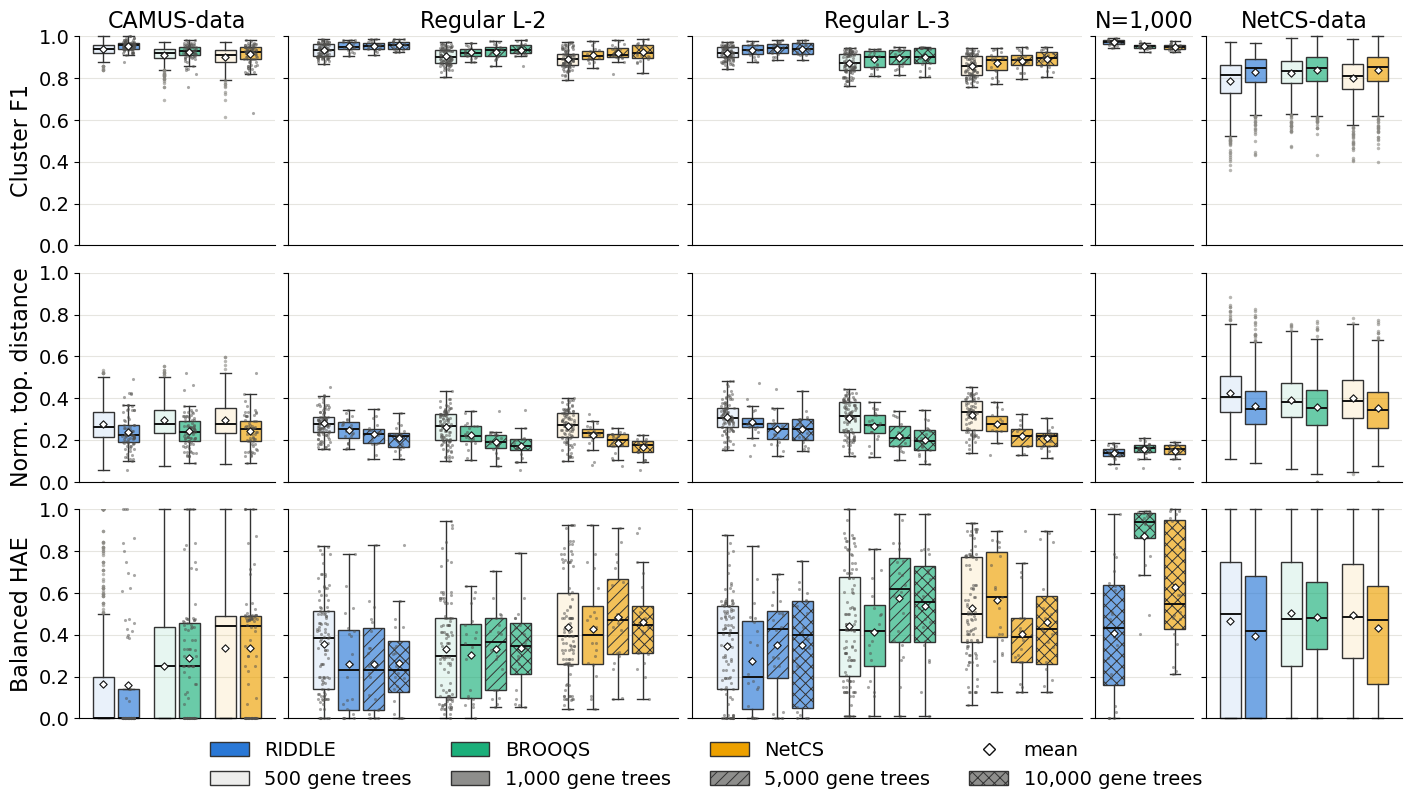

In [10]:
FIGSIZE = (14, 8)
TITLE_FS, LABEL_FS, TICK_FS, LEGEND_FS = 16, 16, 14, 14
YLIM = (0, 1)
GROUP_W = 0.82          # the width one method's boxes share
POINTS_MAX = 100        # every run is drawn as a point up to this many; fliers only above it
GT_ORDER = [500, 1000, 5000, 10000]
GT_ALPHA = dict(zip(GT_ORDER, [0.10, 0.65, 0.65, 0.65]))   # face opacity: 5,000 and 10,000 share 1,000's
GT_HATCH = dict(zip(GT_ORDER, [None, None, "///", "xxx"]))  # ... and are told apart by hatch / cross-hatch
GT_LABEL = {500: "500", 1000: "1,000", 5000: "5,000", 10000: "10,000"}
# this figure's own jitter generator, so it draws nothing from RNG and the bootstrap intervals in S1-S3 stay put
rng3 = np.random.default_rng(20261023)
# each column as wide as it has boxes (methods x gene-tree counts), so every box is the same width on the page;
# False gives equal columns, as in Main Figure 1
WIDTH_BY_BOXES = True
n_boxes = [len(GT_METHODS) * GTA[GTA.corpus == ds].trees.nunique() for ds in CORPORA]

fig, axes = plt.subplots(len(METRICS), len(CORPORA), figsize=FIGSIZE, sharey=True, squeeze=True,
                         layout="constrained",
                         gridspec_kw={"width_ratios": n_boxes if WIDTH_BY_BOXES else [1] * len(CORPORA)})
for j, ds in enumerate(CORPORA):
    G = GTA[GTA.corpus == ds]
    gts = [g for g in GT_ORDER if (G.trees == g).any()]
    step = GROUP_W / len(gts)
    for i, (col, lab, better) in enumerate(METRICS):
        ax = axes[i, j]
        for s, m in enumerate(GT_METHODS):
            for t, g in enumerate(gts):
                pos = s + 1 + (t - (len(gts) - 1) / 2) * step
                v = G.loc[(G.method == m) & (G.trees == g), col].dropna().to_numpy()
                if len(v) == 0:
                    continue
                few = len(v) <= POINTS_MAX
                bp = ax.boxplot([v], positions=[pos], widths=0.85 * step, patch_artist=True, showfliers=not few,
                                medianprops=dict(color="#111111", lw=1.4),
                                whiskerprops=dict(color=EDGE, lw=1), capprops=dict(color=EDGE, lw=1),
                                flierprops=dict(marker=".", ms=5, mfc=MUTED, mec="none", alpha=0.6))
                bp["boxes"][0].set(facecolor=mcolors.to_rgba(COLOR[m], GT_ALPHA[g]), edgecolor=EDGE, linewidth=1,
                                   hatch=GT_HATCH[g])
                # values of exactly 0 or 1 sit on the frame; never unclip the fliers (see Main Figure 1)
                for artist in bp["boxes"] + bp["whiskers"] + bp["caps"] + bp["medians"]:
                    artist.set_clip_on(False)
                if few:
                    ax.scatter(pos + rng3.uniform(-0.25, 0.25, len(v)) * step, v, s=5, color=INK, alpha=0.5,
                               lw=0, zorder=3, clip_on=False)
                ax.scatter([pos], [v.mean()], marker="D", s=14, color="white", edgecolor="#111111", lw=0.8,
                           zorder=4, clip_on=False)
        ax.set_xlim(0.4, len(GT_METHODS) + 0.6)
        ax.set_xticks([])
        ax.set_ylim(*YLIM)
        ax.tick_params(axis="y", labelsize=TICK_FS)
        ax.grid(axis="y", color=GRID, lw=0.8)
        if i == 0:
            ax.set_title(CORPUS_SHORT[ds], fontsize=TITLE_FS)
        if j == 0:
            ax.set_ylabel(lab, fontsize=LABEL_FS)

row1 = [Patch(facecolor=COLOR[m], edgecolor=EDGE, label=m) for m in GT_METHODS]
row1.append(Line2D([], [], marker="D", ls="", color="white", markeredgecolor="#111111", markersize=6, label="mean"))
row2 = [Patch(facecolor=mcolors.to_rgba(INK, GT_ALPHA[g]), edgecolor=EDGE, hatch=GT_HATCH[g],
              label=f"{GT_LABEL[g]} gene trees")
        for g in GT_ORDER]
# a legend fills column by column, so interleaving the two rows lays them out as two rows
fig.legend(handles=[h for pair in zip(row1, row2) for h in pair], loc="outside lower center", ncol=len(row1),
           fontsize=LEGEND_FS, frameon=False)
fig.savefig(FIG_DIR / f"AllDatasets-sec3-1-accuracy-genetrees-{TAG}.png", bbox_inches="tight", dpi=300)
plt.show()

In [11]:
# The numbers behind Figure 3: runs, median and mean per corpus, gene-tree count and method.
rows = []
for ds in CORPORA:
    for g in GT_ORDER:
        for m in GT_METHODS:
            S = GTA[(GTA.corpus == ds) & (GTA.trees == g) & (GTA.method == m)]
            if S.empty:
                continue
            row = {"corpus": CORPUS_SHORT[ds], "gene trees": GT_LABEL[g], "method": m, "runs": len(S)}
            for col, lab, _ in METRICS:
                row[f"{lab} median"] = S[col].median()
                row[f"{lab} mean"] = S[col].mean()
            rows.append(row)
with pd.option_context("display.max_rows", 100):
    display(pd.DataFrame(rows).set_index(["corpus", "gene trees", "method"]).round(4))

runs  Cluster F1 median  Cluster F1 mean  \
corpus      gene trees method                                             
CAMUS-data  500        RIDDLE   400             0.9405           0.9377   
                       BROOQS   400             0.9184           0.9106   
                       NetCS    400             0.9107           0.9007   
            1,000      RIDDLE    80             0.9571           0.9543   
                       BROOQS    80             0.9296           0.9249   
                       NetCS     80             0.9266           0.9128   
Regular L-2 500        RIDDLE   100             0.9328           0.9321   
                       BROOQS   100             0.8990           0.9033   
                       NetCS    100             0.8900           0.8923   
            1,000      RIDDLE    20             0.9498           0.9509   
                       BROOQS    20             0.9201           0.9227   
                       NetCS     20             0.9046           0.9117   
            5,000      RIDDLE    20             0.9537           0.9532   
                       BROOQS    20             0.9331           0.9269   
                       NetCS     20             0.9118           0.9208   
            10,000     RIDDLE    20             0.9587           0.9560   
                       BROOQS    20             0.9318           0.9361   
                       NetCS     20             0.9210           0.9233   
Regular L-3 500        RIDDLE   100             0.9180           0.9190   
                       BROOQS   100             0.8697           0.8720   
                       NetCS    100             0.8592           0.8580   
            1,000      RIDDLE    20             0.9327           0.9323   
                       BROOQS    20             0.9004           0.8893   
                       NetCS     20             0.8878           0.8711   
            5,000      RIDDLE    20             0.9419           0.9395   
                       BROOQS    20             0.9006           0.8963   
                       NetCS     20             0.8859           0.8836   
            10,000     RIDDLE    20             0.9400           0.9404   
                       BROOQS    20             0.8993           0.8984   
                       NetCS     20             0.8965           0.8902   
N=1,000     10,000     RIDDLE    20             0.9711           0.9707   
                       BROOQS    20             0.9521           0.9513   
                       NetCS     20             0.9476           0.9485   
NetCS-data  500        RIDDLE  1200             0.8128           0.7849   
                       BROOQS  1200             0.8317           0.8233   
                       NetCS   1200             0.8119           0.7984   
            1,000      RIDDLE  1200             0.8485           0.8306   
                       BROOQS  1200             0.8462           0.8363   
                       NetCS   1200             0.8513           0.8371   

                               Norm. top. distance median  \
corpus      gene trees method                               
CAMUS-data  500        RIDDLE                      0.2647   
                       BROOQS                      0.2788   
                       NetCS                       0.2787   
            1,000      RIDDLE                      0.2236   
                       BROOQS                      0.2404   
                       NetCS                       0.2516   
Regular L-2 500        RIDDLE                      0.2784   
                       BROOQS                      0.2657   
                       NetCS                       0.2729   
            1,000      RIDDLE                      0.2518   
                       BROOQS                      0.2205   
                       NetCS                       0.2350   
            5,000      RIDDLE                      0.2308   
                       BROOQS           

## Supporting figures

| figure | what it shows that the main figures do not |
|---|---|
| **S1** difficulty axes | each corpus split along its own design axes: CAMUS by n, L-2 / L-3 / N=1000 by ILS, NetCS by level × ILS |
| **S2** reticulation count | accuracy against the true k. It cuts across every corpus but is no corpus's designed stratum, so S1 does not show it |
| **S3** paired differences | the per-cell pairing behind Figure 1. Its boxes are marginal distributions, and a small gap there can still be a consistent win cell by cell, or the reverse |
| **S4** runtime by corpus | Figure 2 unpooled, so you can see which corpus drives each pooled box |

### S1: each corpus along its own difficulty axes

Points are the mean over cells, with a 95% cell-bootstrap interval; methods are dodged.
- **CAMUS** has neither a level axis nor an ILS axis (level-1 throughout), so its axis is n.
- **L-2, L-3 and N=1000** vary ILS through the mean internal branch length in coalescent units.
- **NetCS** varies level and the ILS branch scale.

On both ILS axes, 0.25 is the most ILS. The y axis is [0, 1] (`YLIM`).

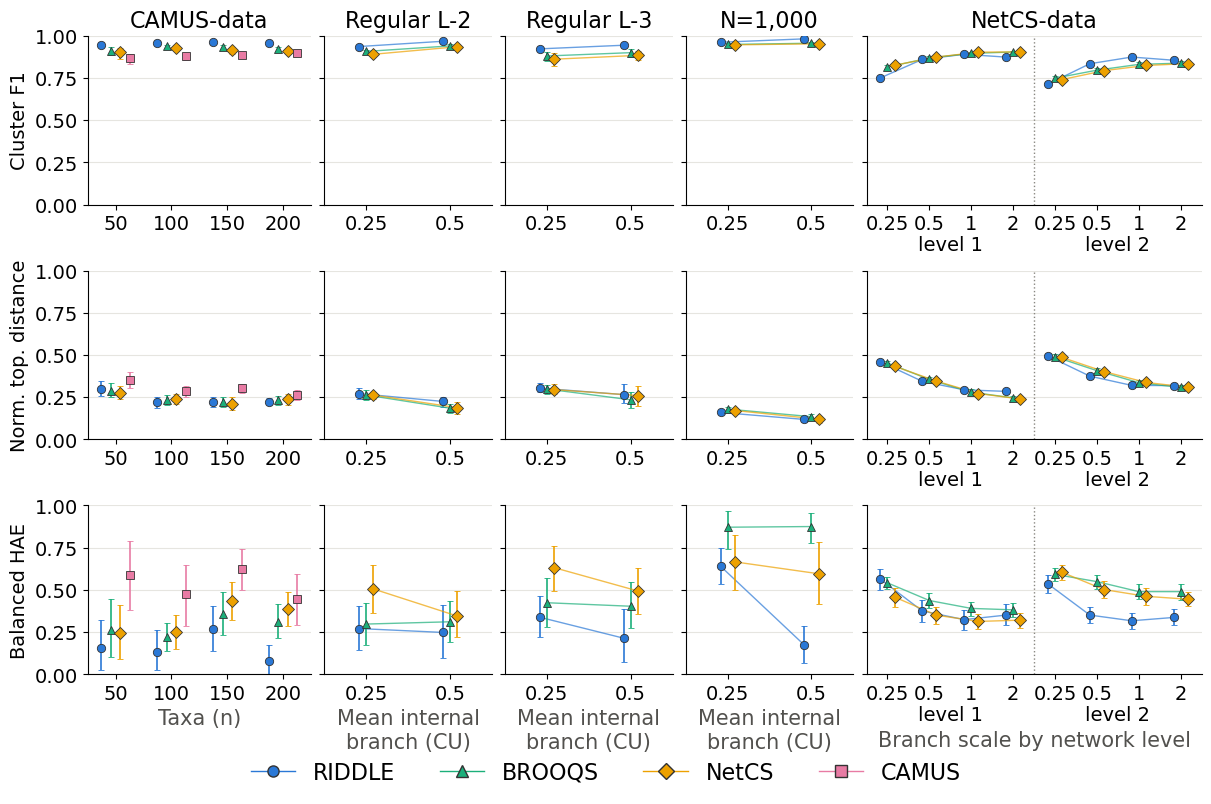

In [19]:
FIGSIZE = (12, 8)
TITLE_FS, LABEL_FS, TICK_FS, LEGEND_FS = 16, 14, 14, 16
YLIM = (0, 1)
DODGE, MS = 0.17, 6        # the dodge at 4 slots; a panel with fewer slots narrows it in proportion
NO_TREND = {"camus"}       # corpora whose axis is not a difficulty trend (CAMUS: n): points, no lines
# per corpus: the `stratum` values in plot order, their tick labels, and the axis name
STRATA = {
    "camus": (["n=50", "n=100", "n=150", "n=200"], ["50", "100", "150", "200"], "Taxa (n)"),
    "l2reg": (["cu=0.25", "cu=0.5"], ["0.25", "0.5"], "Mean internal\nbranch (CU)"),
    "l3reg": (["cu=0.25", "cu=0.5"], ["0.25", "0.5"], "Mean internal\nbranch (CU)"),
    "n1000": (["cu=0.25", "cu=0.5"], ["0.25", "0.5"], "Mean internal\nbranch (CU)"),
    "netcs": ([f"L{lv} ILS {s}" for lv in (1, 2) for s in ("0.25", "0.5", "1.0", "2.0")],
              ["0.25", "0.5", "1", "2"] * 2, "Branch scale by network level"),
}

# a column per corpus, as wide as its strata are many but never under 3 or over 6 slots: a 2-stratum column
# needs room for its title, and NetCS's 8 would squeeze the rest
fig, axes = plt.subplots(len(METRICS), len(CORPORA), figsize=FIGSIZE, sharey=True, squeeze=False,
                         layout="constrained",
                         gridspec_kw={"width_ratios": [min(max(len(STRATA[ds][0]), 3), 6) for ds in CORPORA]})
for j, ds in enumerate(CORPORA):
    A = ACC[ACC.corpus == ds]
    strata, ticklabels, xlabel = STRATA[ds]
    assert set(A.stratum) == set(strata), (ds, set(A.stratum) ^ set(strata))
    segment = [s[:2] if ds == "netcs" else "" for s in strata]     # lines never join NetCS's two levels
    methods = [m for m in METHODS if (A.method == m).any()]
    for i, (col, lab, better) in enumerate(METRICS):
        ax = axes[i, j]
        for k, m in enumerate(methods):
            off = (k - (len(methods) - 1) / 2) * DODGE * min(1, len(strata) / 4)
            mus, los, his = [], [], []
            for st in strata:
                v = A.loc[(A.method == m) & (A.stratum == st), col].dropna().to_numpy()
                if len(v) == 0:
                    mus.append(np.nan); los.append(np.nan); his.append(np.nan)
                    continue
                bs = RNG.choice(v, size=(N_BOOT, len(v)), replace=True).mean(axis=1)
                lo, hi = np.percentile(bs, [2.5, 97.5])
                mus.append(v.mean()); los.append(lo); his.append(hi)
            xs, mus, los, his = np.arange(len(strata)) + off, np.array(mus), np.array(los), np.array(his)
            for seg in dict.fromkeys(segment) if ds not in NO_TREND else []:
                idx = [x for x, sg in enumerate(segment) if sg == seg]
                ax.plot(xs[idx], mus[idx], color=COLOR[m], lw=1, alpha=0.7)
            ax.errorbar(xs, mus, yerr=[mus - los, his - mus], fmt=MARKER[m], color=COLOR[m], ms=MS, mec=EDGE,
                        mew=0.6, capsize=2, lw=1.2, ls="none", label=m)
        ax.set_xticks(range(len(strata)))
        ax.set_xticklabels(ticklabels, fontsize=TICK_FS)
        ax.set_xlim(-0.5, len(strata) - 0.5)
        if ds == "netcs":
            ax.axvline(3.5, color=MUTED, lw=1, ls=":")
            ax.set_xticks([1.5, 5.5], minor=True)
            ax.set_xticklabels(["level 1", "level 2"], minor=True, fontsize=TICK_FS)
            ax.tick_params(axis="x", which="minor", length=0, pad=1.6 * TICK_FS)   # below the ILS labels
        if i == len(METRICS) - 1:
            ax.set_xlabel(xlabel, fontsize=TICK_FS + 1, color=INK)
        ax.set_ylim(*YLIM)
        ax.tick_params(axis="y", labelsize=TICK_FS)
        ax.grid(axis="y", color=GRID, lw=0.8)
        if i == 0:
            ax.set_title(CORPUS_SHORT[ds], fontsize=TITLE_FS)   # narrow columns
        if j == 0:
            ax.set_ylabel(lab, fontsize=LABEL_FS)

handles = [Line2D([], [], marker=MARKER[m], color=COLOR[m], markeredgecolor=EDGE, ms=8, lw=1, label=m)
           for m in METHODS]
fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), fontsize=LEGEND_FS, frameon=False)
fig.savefig(FIG_DIR / f"AllDatasets-sec3-1-strata-{TAG}.png", bbox_inches="tight", dpi=300)
plt.show()

In [13]:
# The numbers behind S1: cells and mean per corpus, stratum and method.
rows = []
for ds in CORPORA:
    A = ACC[ACC.corpus == ds]
    for st in STRATA[ds][0]:
        for m in METHODS:
            S = A[(A.stratum == st) & (A.method == m)]
            if S.empty:
                continue
            rows.append({"corpus": CORPUS_SHORT[ds], "stratum": st, "method": m, "cells": S.cell.nunique(),
                         **{f"{lab} mean": S[col].mean() for col, lab, _ in METRICS}})
with pd.option_context("display.max_rows", 200):
    display(pd.DataFrame(rows).set_index(["corpus", "stratum", "method"]).round(4))

cells  Cluster F1 mean  \
corpus      stratum     method                           
CAMUS-data  n=50        RIDDLE     20           0.9471   
                        BROOQS     20           0.9114   
                        NetCS      20           0.9005   
                        CAMUS      20           0.8650   
            n=100       RIDDLE     20           0.9543   
                        BROOQS     20           0.9371   
                        NetCS      20           0.9272   
                        CAMUS      20           0.8784   
            n=150       RIDDLE     20           0.9599   
                        BROOQS     20           0.9310   
                        NetCS      20           0.9128   
                        CAMUS      20           0.8834   
            n=200       RIDDLE     20           0.9558   
                        BROOQS     20           0.9203   
                        NetCS      20           0.9107   
                        CAMUS      20           0.8965   
Regular L-2 cu=0.25     RIDDLE     10           0.9353   
                        BROOQS     10           0.9064   
                        NetCS      10           0.8895   
            cu=0.5      RIDDLE     10           0.9665   
                        BROOQS     10           0.9389   
                        NetCS      10           0.9340   
Regular L-3 cu=0.25     RIDDLE     10           0.9216   
                        BROOQS     10           0.8794   
                        NetCS      10           0.8603   
            cu=0.5      RIDDLE     10           0.9430   
                        BROOQS     10           0.8991   
                        NetCS      10           0.8830   
N=1,000     cu=0.25     RIDDLE     10           0.9606   
                        BROOQS     10           0.9476   
                        NetCS      10           0.9453   
            cu=0.5      RIDDLE     10           0.9808   
                        BROOQS     10           0.9549   
                        NetCS      10           0.9517   
NetCS-data  L1 ILS 0.25 RIDDLE    150           0.7496   
                        BROOQS    150           0.8138   
                        NetCS     150           0.8248   
            L1 ILS 0.5  RIDDLE    150           0.8590   
                        BROOQS    150           0.8677   
                        NetCS     150           0.8730   
            L1 ILS 1.0  RIDDLE    150           0.8894   
                        BROOQS    150           0.8950   
                        NetCS     150           0.9019   
            L1 ILS 2.0  RIDDLE    150           0.8727   
                        BROOQS    150           0.9029   
                        NetCS     150           0.9038   
            L2 ILS 0.25 RIDDLE    150           0.7130   
                        BROOQS    150           0.7481   
                        NetCS     150           0.7401   
            L2 ILS 0.5  RIDDLE    150           0.8335   
                        BROOQS    150           0.7954   
                        NetCS     150           0.7926   
            L2 ILS 1.0  RIDDLE    150           0.8731   
                        BROOQS    150           0.8297   
                        NetCS     150           0.8232   
            L2 ILS 2.0  RIDDLE    150           0.8543   
                        BROOQS    150           0.8370   
                        NetCS     150           0.8344   

                                Norm. top. distance mean  Balanced HAE mean  
corpus      stratum     method                                               
CAMUS-data  n=50        RIDDLE                    0.2991             0.1582  
                        BROOQS                    0.2884             0.2625  
                        NetCS                     0.2769             0.2442  
                        CAMUS                     0.3504             0.5900  
            n=100       RIDDLE                    0.2193             0.1309  
     

### S2: accuracy against the true reticulation count

Same layout as S1, with the true k of each cell (from its `CELLS.tsv`) on the x axis.
- The tail is binned per corpus by `K_BINS`, so no bin is a single network. Tick labels give the cells in each bin.
- On NetCS each network appears at four ILS levels, so a NetCS bin counts conditions, not distinct networks.

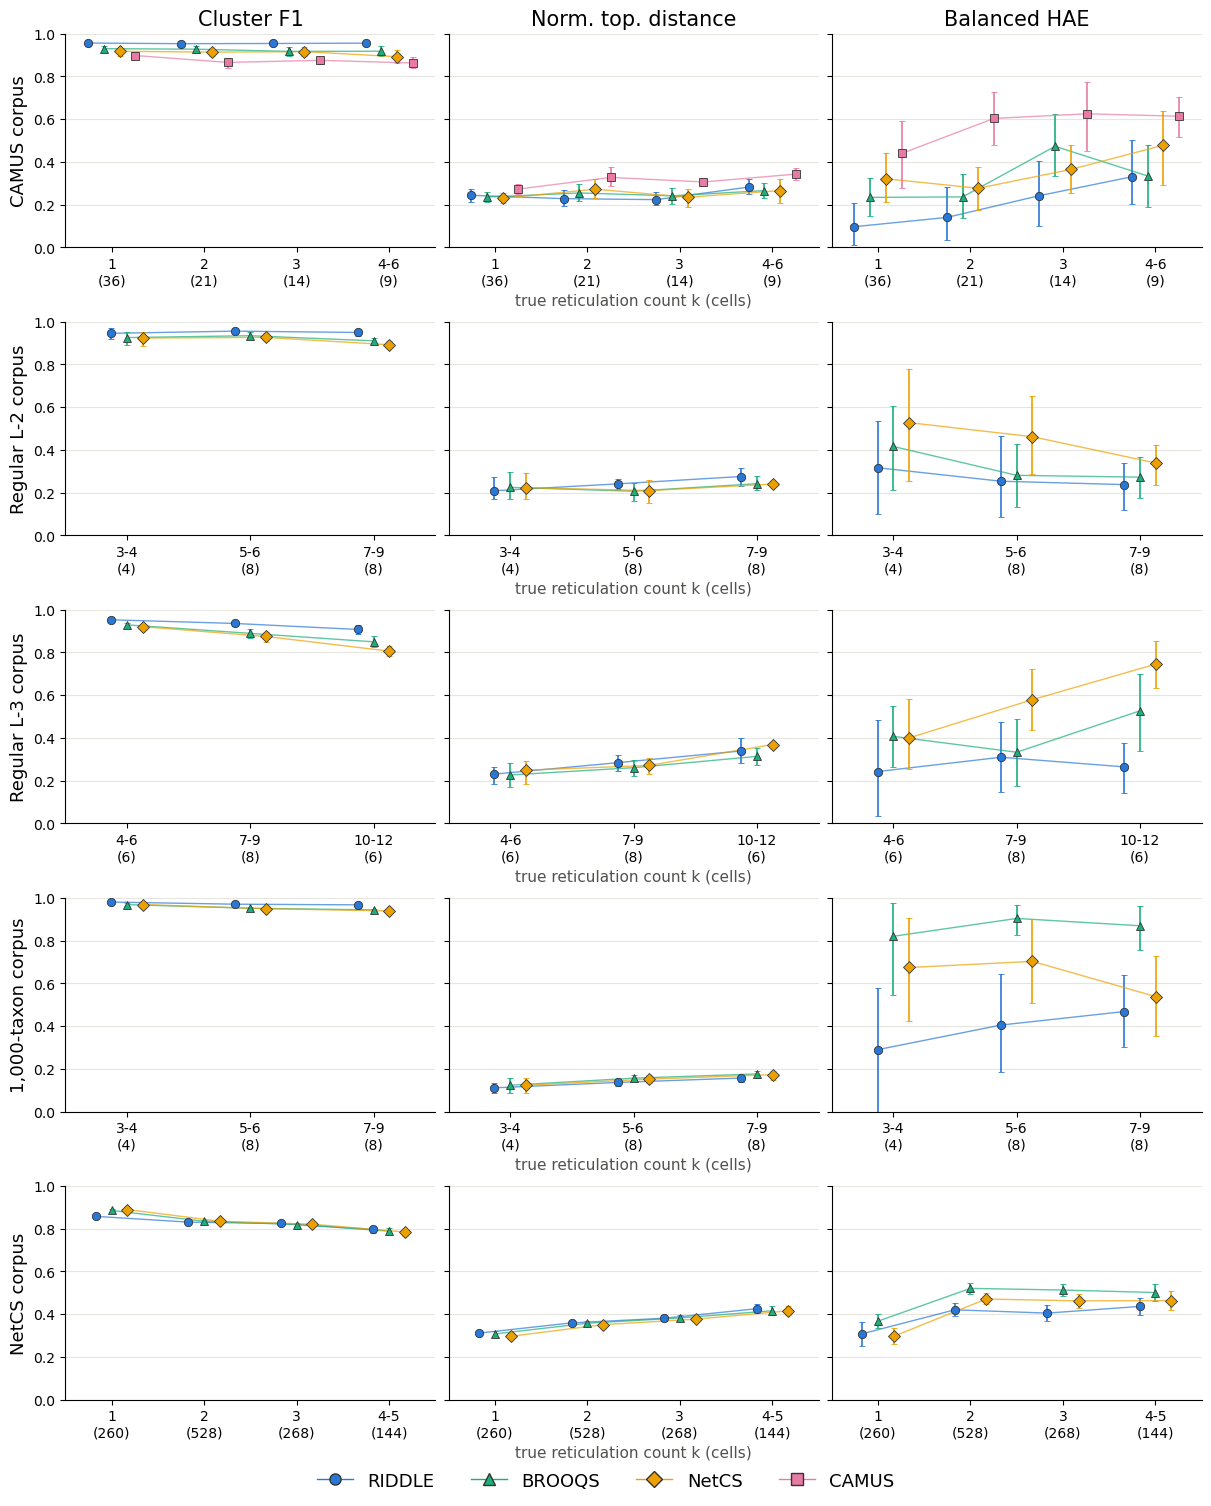

In [14]:
FIGSIZE = (12, 15)
TITLE_FS, LABEL_FS, TICK_FS, LEGEND_FS = 15, 13, 10, 13
YLIM = (0, 1)
DODGE, MS = 0.17, 6        # the dodge at 4 slots; a panel with fewer slots narrows it in proportion
# per corpus: (lowest k, highest k, label) for each bin, in plot order
K_BINS = {
    "camus": [(1, 1, "1"), (2, 2, "2"), (3, 3, "3"), (4, 6, "4-6")],
    "l2reg": [(3, 4, "3-4"), (5, 6, "5-6"), (7, 9, "7-9")],
    "l3reg": [(4, 6, "4-6"), (7, 9, "7-9"), (10, 12, "10-12")],
    "n1000": [(3, 4, "3-4"), (5, 6, "5-6"), (7, 9, "7-9")],
    "netcs": [(1, 1, "1"), (2, 2, "2"), (3, 3, "3"), (4, 5, "4-5")],
}

fig, axes = plt.subplots(len(CORPORA), len(METRICS), figsize=FIGSIZE, sharey=True, squeeze=False,
                         layout="constrained")
for i, ds in enumerate(CORPORA):
    A = ACC[ACC.corpus == ds]
    bins = K_BINS[ds]
    in_bin = [A.k.between(lo, hi) for lo, hi, _ in bins]
    assert sum(b.astype(int) for b in in_bin).eq(1).all(), f"{ds}: K_BINS must cover every k exactly once"
    ticklabels = [f"{lab}\n({A.loc[b, 'cell'].nunique()})" for (_, _, lab), b in zip(bins, in_bin)]
    methods = [m for m in METHODS if (A.method == m).any()]
    for j, (col, lab, better) in enumerate(METRICS):
        ax = axes[i, j]
        for k, m in enumerate(methods):
            off = (k - (len(methods) - 1) / 2) * DODGE * min(1, len(bins) / 4)
            mus, los, his = [], [], []
            for b in in_bin:
                v = A.loc[b & (A.method == m), col].dropna().to_numpy()
                if len(v) == 0:
                    mus.append(np.nan); los.append(np.nan); his.append(np.nan)
                    continue
                bs = RNG.choice(v, size=(N_BOOT, len(v)), replace=True).mean(axis=1)
                lo, hi = np.percentile(bs, [2.5, 97.5])
                mus.append(v.mean()); los.append(lo); his.append(hi)
            xs, mus, los, his = np.arange(len(bins)) + off, np.array(mus), np.array(los), np.array(his)
            ax.plot(xs, mus, color=COLOR[m], lw=1, alpha=0.7)
            ax.errorbar(xs, mus, yerr=[mus - los, his - mus], fmt=MARKER[m], color=COLOR[m], ms=MS, mec=EDGE,
                        mew=0.6, capsize=2, lw=1.2, ls="none", label=m)
        ax.set_xticks(range(len(bins)))
        ax.set_xticklabels(ticklabels, fontsize=TICK_FS)
        ax.set_xlim(-0.5, len(bins) - 0.5)
        if j == 1:
            ax.set_xlabel("true reticulation count k (cells)", fontsize=TICK_FS + 1, color=INK)
        ax.set_ylim(*YLIM)
        ax.tick_params(axis="y", labelsize=TICK_FS)
        ax.grid(axis="y", color=GRID, lw=0.8)
        if i == 0:
            ax.set_title(lab, fontsize=TITLE_FS)
        if j == 0:
            ax.set_ylabel(CORPUS_TITLE[ds], fontsize=LABEL_FS)

handles = [Line2D([], [], marker=MARKER[m], color=COLOR[m], markeredgecolor=EDGE, ms=8, lw=1, label=m)
           for m in METHODS]
fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), fontsize=LEGEND_FS, frameon=False)
fig.savefig(FIG_DIR / f"AllDatasets-sec3-1-retic-{TAG}.png", bbox_inches="tight")
plt.show()

In [15]:
# The numbers behind S2: cells and mean per corpus, k bin and method.
rows = []
for ds in CORPORA:
    A = ACC[ACC.corpus == ds]
    for lo, hi, blab in K_BINS[ds]:
        for m in METHODS:
            S = A[A.k.between(lo, hi) & (A.method == m)]
            if S.empty:
                continue
            rows.append({"corpus": CORPUS_SHORT[ds], "k": blab, "method": m, "cells": S.cell.nunique(),
                         **{f"{lab} mean": S[col].mean() for col, lab, _ in METRICS}})
with pd.option_context("display.max_rows", 200):
    display(pd.DataFrame(rows).set_index(["corpus", "k", "method"]).round(4))

cells  Cluster F1 mean  Norm. top. distance mean  \
corpus      k     method                                                     
CAMUS-data  1     RIDDLE     36           0.9555                    0.2431   
                  BROOQS     36           0.9291                    0.2349   
                  NetCS      36           0.9170                    0.2298   
                  CAMUS      36           0.8971                    0.2726   
            2     RIDDLE     21           0.9525                    0.2276   
                  BROOQS     21           0.9267                    0.2542   
                  NetCS      21           0.9130                    0.2718   
                  CAMUS      21           0.8650                    0.3269   
            3     RIDDLE     14           0.9534                    0.2229   
                  BROOQS     14           0.9165                    0.2408   
                  NetCS      14           0.9153                    0.2342   
                  CAMUS      14           0.8746                    0.3056   
            4-6   RIDDLE      9           0.9550                    0.2818   
                  BROOQS      9           0.9173                    0.2653   
                  NetCS       9           0.8916                    0.2653   
                  CAMUS       9           0.8623                    0.3424   
Regular L-2 3-4   RIDDLE      4           0.9452                    0.2088   
                  BROOQS      4           0.9254                    0.2245   
                  NetCS       4           0.9232                    0.2229   
            5-6   RIDDLE      8           0.9554                    0.2410   
                  BROOQS      8           0.9340                    0.2066   
                  NetCS       8           0.9261                    0.2095   
            7-9   RIDDLE      8           0.9492                    0.2754   
                  BROOQS      8           0.9100                    0.2417   
                  NetCS       8           0.8916                    0.2400   
Regular L-3 4-6   RIDDLE      6           0.9527                    0.2309   
                  BROOQS      6           0.9290                    0.2268   
                  NetCS       6           0.9207                    0.2493   
            7-9   RIDDLE      8           0.9357                    0.2844   
                  BROOQS      8           0.8893                    0.2609   
                  NetCS       8           0.8746                    0.2715   
            10-12 RIDDLE      6           0.9074                    0.3392   
                  BROOQS      6           0.8496                    0.3137   
                  NetCS       6           0.8061                    0.3692   
N=1,000     3-4   RIDDLE      4           0.9799                    0.1109   
                  BROOQS      4           0.9680                    0.1229   
                  NetCS       4           0.9683                    0.1230   
            5-6   RIDDLE      8           0.9699                    0.1361   
                  BROOQS      8           0.9509                    0.1561   
                  NetCS       8           0.9487                    0.1516   
            7-9   RIDDLE      8           0.9669                    0.1566   
                  BROOQS      8           0.9433                    0.1757   
                  NetCS       8           0.9385                    0.1726   
NetCS-data  1     RIDDLE    260           0.8572                    0.3112   
                  BROOQS    260           0.8848                    0.3071   
                  NetCS     260           0.8892                    0.2961   
            2     RIDDLE    528           0.8302                    0.3589   
                  BROOQS    528           0.8343                    0.3573   
                  NetCS     528           0.8344                    0.3506   
            3     RIDDLE    268           0.8240

### S3: RIDDLE against each comparator, cell by cell

For every cell where both methods have a value, the difference is **oriented so that above 0 means RIDDLE is
better**:
- RIDDLE − other for cluster F1;
- other − RIDDLE for the Nakhleh distance and the HAE.

Points are the mean paired difference, with a 95% cell-bootstrap interval. The table after the figure gives the
win, tie and loss counts and a Wilcoxon signed-rank test (Pratt's zero handling).

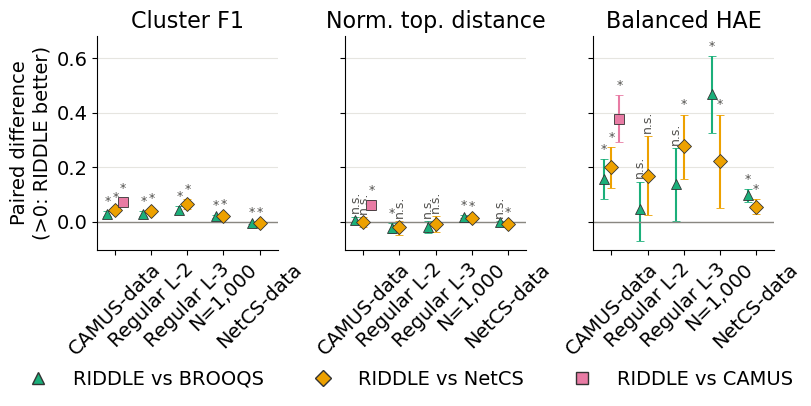

pairs  mean (>0: RIDDLE better)  \
metric              corpus      vs                                        
Cluster F1          CAMUS-data  BROOQS     80                    0.0293   
                    Regular L-2 BROOQS     20                    0.0282   
                    Regular L-3 BROOQS     20                    0.0430   
                    N=1,000     BROOQS     20                    0.0194   
                    NetCS-data  BROOQS   1197                   -0.0056   
                    CAMUS-data  NetCS      80                    0.0415   
                    Regular L-2 NetCS      20                    0.0391   
                    Regular L-3 NetCS      19                    0.0629   
                    N=1,000     NetCS      20                    0.0222   
                    NetCS-data  NetCS    1188                   -0.0062   
                    CAMUS-data  CAMUS      80                    0.0735   
Norm. top. distance CAMUS-data  BROOQS     80                    0.0045   
                    Regular L-2 BROOQS     20                   -0.0241   
                    Regular L-3 BROOQS     20                   -0.0182   
                    N=1,000     BROOQS     20                    0.0180   
                    NetCS-data  BROOQS   1197                   -0.0024   
                    CAMUS-data  NetCS      65                   -0.0013   
                    Regular L-2 NetCS      19                   -0.0206   
                    Regular L-3 NetCS      14                   -0.0095   
                    N=1,000     NetCS      13                    0.0143   
                    NetCS-data  NetCS    1188                   -0.0088   
                    CAMUS-data  CAMUS      80                    0.0606   
Balanced HAE        CAMUS-data  BROOQS     77                    0.1557   
                    Regular L-2 BROOQS     20                    0.0448   
                    Regular L-3 BROOQS     20                    0.1375   
                    N=1,000     BROOQS     20                    0.4661   
                    NetCS-data  BROOQS   1182                    0.0964   
                    CAMUS-data  NetCS      76                    0.1996   
                    Regular L-2 NetCS      20                    0.1660   
                    Regular L-3 NetCS      19                    0.2787   
                    N=1,000     NetCS      20                    0.2239   
                    NetCS-data  NetCS    1138                    0.0551   
                    CAMUS-data  CAMUS      80                    0.3746   

                                        median  RIDDLE better  tied  \
metric              corpus      vs                                    
Cluster F1          CAMUS-data  BROOQS  0.0271             59     6   
                    Regular L-2 BROOQS  0.0308             18     0   
                    Regular L-3 BROOQS  0.0397             18     0   
                    N=1,000     BROOQS  0.0212             20     0   
                    NetCS-data  BROOQS -0.0098            533     9   
                    CAMUS-data  NetCS   0.0335             64     4   
                    Regular L-2 NetCS   0.0409             20     0   
                    Regular L-3 NetCS   0.0500             18     0   
                    N=1,000     NetCS   0.0214             20     0   
                    NetCS-data  NetCS  -0.0121            514    14   
                    CAMUS-data  CAMUS   0.0685             72     5   
Norm. top. distance CAMUS-data  BROOQS  0.0030             41     3   
                    Regular L-2 BROOQS -0.0322              7     0   
                    Regular L-3 BROOQS -0.0050              8     0   
                    N=1,000     BROOQS  0.0200             19     0   
                    NetCS-data  BROOQS -0.0031            576     5   
                    CAMUS-data  NetCS   0.0000             30     3   
                    Regular L-2 NetCS  -0.0180              8    

In [16]:
FIGSIZE = (8, 4)
TITLE_FS, LABEL_FS, TICK_FS, LEGEND_FS = 16, 14, 14, 14
COMPARATORS = ["BROOQS", "NetCS", "CAMUS"]
DODGE, MS = 0.22, 7
SIG_ALPHA = 0.05                 # "*" above a comparison whose Wilcoxon p is below this, "n.s." otherwise
SIG_FS, SIG_PAD = 9, 0.012       # label font size, and its gap above the upper CI end (data units)
SIG_HEADROOM = 0.08              # room added above the tallest label, as a fraction of the y range
SIG_ROT_NS = 90                  # "n.s." is set vertically: horizontal, neighbouring labels collide

fig, axes = plt.subplots(1, len(METRICS), figsize=FIGSIZE, squeeze=False, sharey=True,
                         layout="constrained")
rows = []
y_top = -np.inf
for j, (col, lab, better) in enumerate(METRICS):
    ax = axes[0, j]
    sign = 1 if better == "higher" else -1
    for c, other in enumerate(COMPARATORS):
        xs, mus, los, his, ps = [], [], [], [], []
        for x, ds in enumerate(CORPORA):
            p = ACC[ACC.corpus == ds].pivot(index="cell", columns="method", values=col)
            if other not in p:
                continue
            d = (sign * (p["RIDDLE"] - p[other])).dropna().to_numpy()
            if len(d) == 0:
                continue
            bs = RNG.choice(d, size=(N_BOOT, len(d)), replace=True).mean(axis=1)
            lo, hi = np.percentile(bs, [2.5, 97.5])
            xs.append(x + (c - (len(COMPARATORS) - 1) / 2) * DODGE)
            mus.append(d.mean()); los.append(lo); his.append(hi)
            pval = wilcoxon(d, zero_method="pratt").pvalue if (d != 0).any() else np.nan
            ps.append(pval)
            rows.append({"metric": lab, "corpus": CORPUS_SHORT[ds], "vs": other, "pairs": len(d),
                         "mean (>0: RIDDLE better)": d.mean(), "median": np.median(d),
                         "RIDDLE better": int((d > 0).sum()), "tied": int((d == 0).sum()),
                         "RIDDLE worse": int((d < 0).sum()),
                         "Wilcoxon p": pval})
        if xs:
            mus, los, his = np.array(mus), np.array(los), np.array(his)
            ax.errorbar(xs, mus, yerr=[mus - los, his - mus], fmt=MARKER[other], color=COLOR[other], ms=MS,
                        mec=EDGE, mew=0.6, capsize=3, lw=1.5, ls="none", label=f"RIDDLE vs {other}")
            # significance of each comparison (all tied: no p, so n.s.)
            for x_, hi_, p_ in zip(xs, his, ps):
                sig = p_ < SIG_ALPHA
                ax.text(x_, hi_ + SIG_PAD, "*" if sig else "n.s.", ha="center", va="bottom",
                        rotation=0 if sig else SIG_ROT_NS, fontsize=SIG_FS, color=INK)
            y_top = max(y_top, his.max() + SIG_PAD)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_xticks(range(len(CORPORA)))
    ax.set_xticklabels([CORPUS_SHORT[ds] for ds in CORPORA], fontsize=TICK_FS, rotation=45)
    ax.set_xlim(-0.5, len(CORPORA) - 0.5)
    ax.tick_params(axis="y", labelsize=TICK_FS)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_title(lab, fontsize=TITLE_FS)
y_lo, y_hi = axes[0, 0].get_ylim()          # shared: one call sets every panel
axes[0, 0].set_ylim(y_lo, max(y_hi, y_top + SIG_HEADROOM * (y_hi - y_lo)))
axes[0, 0].set_ylabel("Paired difference\n(>0: RIDDLE better)", fontsize=LABEL_FS)
handles = [Line2D([], [], marker=MARKER[o], ls="", color=COLOR[o], markeredgecolor=EDGE, ms=8,
                  label=f"RIDDLE vs {o}") for o in COMPARATORS]
fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), fontsize=LEGEND_FS, frameon=False)
fig.savefig(FIG_DIR / f"AllDatasets-sec3-1-paired-{TAG}.png", bbox_inches="tight", dpi=300)
plt.show()

paired = pd.DataFrame(rows).set_index(["metric", "corpus", "vs"])
paired["Wilcoxon p"] = paired["Wilcoxon p"].map(lambda p: f"{p:.2g}" if p == p else "all tied")
with pd.option_context("display.max_rows", 100):
    display(paired.round(4))

In [17]:
# S3's table as LaTeX, to paste into the paper (needs \usepackage{booktabs, multirow}).  Rows: metric, corpus,
# comparator.  The differences are oriented as in the figure: > 0 means RIDDLE is better.
DECIMALS = 4
POSITION = "t"
LABEL = "tab:sec3-1-paired"
CAPTION = (r"Paired per-cell differences between RIDDLE and each comparator, oriented so that a positive value "
           r"favours RIDDLE: RIDDLE $-$ other for cluster F1, other $-$ RIDDLE for the normalised Nakhleh distance "
           r"and the balanced HAE. $n$: cells where both methods have a value. Better / tied / worse: cells. "
           r"$p$: two-sided Wilcoxon signed-rank test (Pratt's zero handling).")
HEADER = {"pairs": "$n$", "mean (>0: RIDDLE better)": r"Mean $\Delta$", "median": r"Median $\Delta$",
          "RIDDLE better": "Better", "tied": "Tied", "RIDDLE worse": "Worse", "Wilcoxon p": "$p$"}

tex = paired.reset_index()
# metric, then corpus, then comparator, each in the figure's order
tex["metric"] = pd.Categorical(tex.metric, [lab for _, lab, _ in METRICS], ordered=True)
tex["corpus"] = pd.Categorical(tex.corpus, [CORPUS_SHORT[ds] for ds in CORPORA], ordered=True)
tex["vs"] = pd.Categorical(tex.vs, COMPARATORS, ordered=True)
tex = tex.sort_values(["metric", "corpus", "vs"])
for col in ["mean (>0: RIDDLE better)", "median"]:
    tex[col] = [rf"${x:.{DECIMALS}f}$" for x in tex[col]]
p_tex = []
for s in tex["Wilcoxon p"]:
    if s == "all tied":
        p_tex.append("--")
    elif float(s) < 1e-3:
        mant, exp = f"{float(s):.1e}".split("e")
        p_tex.append(rf"${mant}\times10^{{{int(exp)}}}$")
    else:
        p_tex.append(f"{float(s):.2g}")
tex["Wilcoxon p"] = p_tex
tex = (tex.set_index(["metric", "corpus", "vs"]).rename(columns=HEADER)
          .rename_axis(["Metric", "Corpus", "vs."]))
latex = tex.to_latex(escape=False, multirow=True, column_format="lll" + "r" * tex.shape[1],
                     caption=CAPTION, label=LABEL, position=POSITION)
# booktabs rules instead of pandas' \cline: \midrule between metrics, \cmidrule between corpora, none at the end
n_cols = tex.index.nlevels + tex.shape[1]
latex = latex.replace(f"\\cline{{1-{n_cols}}} \\cline{{2-{n_cols}}}\n\\bottomrule", "\\bottomrule")
latex = latex.replace(f"\\cline{{1-{n_cols}}} \\cline{{2-{n_cols}}}", "\\midrule")
latex = latex.replace(f"\\cline{{2-{n_cols}}}", f"\\cmidrule(l){{2-{n_cols}}}")
# one header row: the index names beside the column names, not on a row of their own
lines = latex.splitlines()
top = lines.index("\\toprule")
lines[top + 1:top + 3] = [" & ".join(list(tex.index.names) + list(tex.columns)) + " \\\\"]
latex = "\n".join(lines)
print(latex)

\begin{table}[t]
\caption{Paired per-cell differences between RIDDLE and each comparator, oriented so that a positive value favours RIDDLE: RIDDLE $-$ other for cluster F1, other $-$ RIDDLE for the normalised Nakhleh distance and the balanced HAE. $n$: cells where both methods have a value. Better / tied / worse: cells. $p$: two-sided Wilcoxon signed-rank test (Pratt's zero handling).}
\label{tab:sec3-1-paired}
\begin{tabular}{lllrrrrrrr}
\toprule
Metric & Corpus & vs. & $n$ & Mean $\Delta$ & Median $\Delta$ & Better & Tied & Worse & $p$ \\
\midrule
\multirow[t]{11}{*}{Cluster F1} & \multirow[t]{3}{*}{CAMUS-data} & BROOQS & 80 & $0.0293$ & $0.0271$ & 59 & 6 & 15 & $2.7\times10^{-9}$ \\
 &  & NetCS & 80 & $0.0415$ & $0.0335$ & 64 & 4 & 12 & $1.8\times10^{-10}$ \\
 &  & CAMUS & 80 & $0.0735$ & $0.0685$ & 72 & 5 & 3 & $2.4\times10^{-14}$ \\
\cmidrule(l){2-10}
 & \multirow[t]{2}{*}{Regular L-2} & BROOQS & 20 & $0.0282$ & $0.0308$ & 18 & 0 & 2 & $3.6\times10^{-5}$ \\
 &  & NetCS & 20 & $0.0

### S4: runtime by corpus

This is Figure 2 with nothing pooled: one panel per corpus, n within each, and the same slots, hatching and
whiskers.
- NetCS supplies most of the cells at 50, 100 and 200 (about 400 per n, against 20 from each other corpus), so
  it sets the solid boxes there.
- The hatched boxes come from CAMUS, plus L-2 and L-3 at 200.
- Both the L-2 / L-3 TOB and CAMUS's were inferred from 1,000 gene trees, but on different hosts and networks.
  The L-2 / L-3 TOB is TREE-QMC's self-reported Linux wall time; CAMUS's is the Mac re-run.

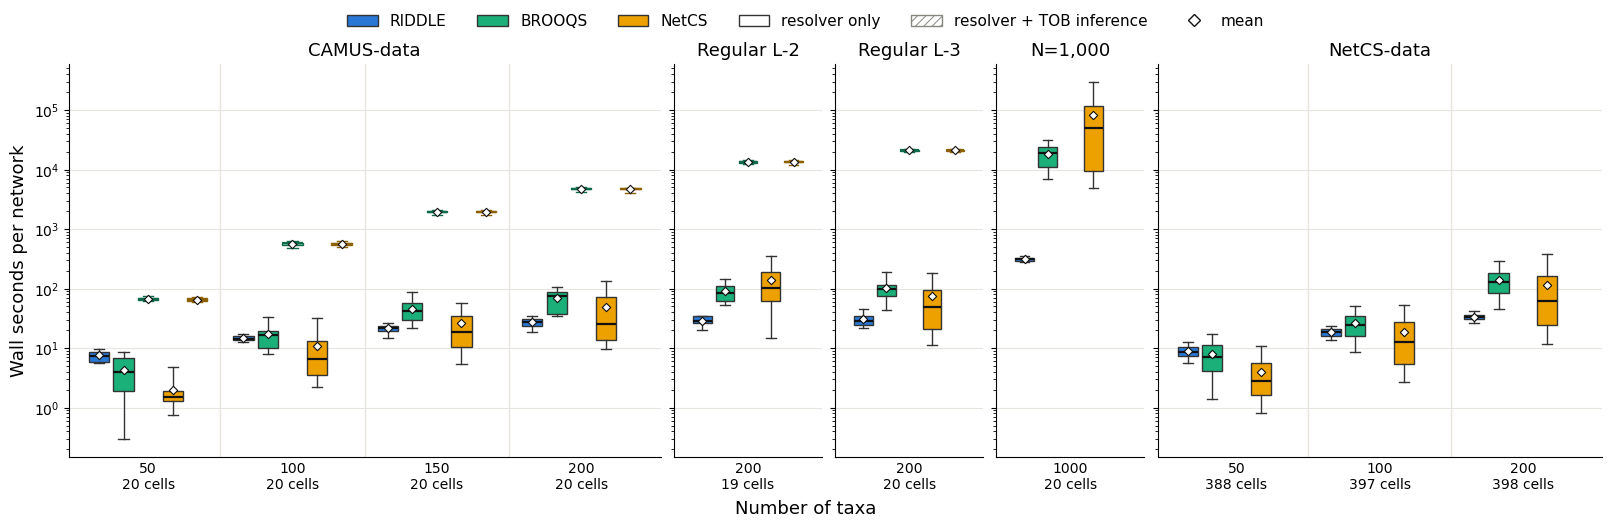

In [18]:
FIGSIZE = (16, 5.2)
TITLE_FS, LABEL_FS, TICK_FS, LEGEND_FS = 13, 13, 10, 11
SLOTS = [("RIDDLE", "resolver_s", False),
         ("BROOQS", "resolver_s", False), ("BROOQS", "with_tob_s", True),
         ("NetCS", "resolver_s", False), ("NetCS", "with_tob_s", True)]
SLOT_STEP, BOX_W = 0.17, 0.14
WHIS = (5, 95)
TOB_TINT, HATCH = 0.45, "////"
TOB_DARK = 0.6

N_OF = {ds: sorted(RT.loc[RT.corpus == ds, "n_nom"].unique()) for ds in CORPORA}
fig, axes = plt.subplots(1, len(CORPORA), figsize=FIGSIZE, sharey=True, layout="constrained",
                         gridspec_kw={"width_ratios": [len(N_OF[ds]) for ds in CORPORA]})
for ax, ds in zip(axes, CORPORA):
    R = RT[RT.corpus == ds]
    ticklabels = []
    for x, n in enumerate(N_OF[ds]):
        S = R[R.n_nom == n]
        for s, (m, col, tob) in enumerate(SLOTS):
            v = S.loc[S.method == m, col].dropna().to_numpy()
            if len(v) == 0:
                continue
            pos = x + (s - (len(SLOTS) - 1) / 2) * SLOT_STEP
            rgb = np.array(mcolors.to_rgb(COLOR[m]))
            face = tuple(1 - TOB_TINT * (1 - rgb)) if tob else COLOR[m]
            line = tuple(TOB_DARK * rgb) if tob else EDGE
            bp = ax.boxplot([v], positions=[pos], widths=BOX_W, whis=WHIS, patch_artist=True, showfliers=False,
                            medianprops=dict(color="#111111" if not tob else line, lw=1.6),
                            whiskerprops=dict(color=line, lw=1), capprops=dict(color=line, lw=1))
            bp["boxes"][0].set(facecolor=face, edgecolor=line, linewidth=1, hatch=HATCH if tob else None)
            ax.scatter([pos], [v.mean()], marker="D", s=18, color="white", edgecolor="#111111", lw=0.8,
                       zorder=4)
        ticklabels.append(f"{n}\n{S.loc[S.method == 'RIDDLE'].cell.nunique()} cells")
    ax.set_yscale("log")
    ax.set_xticks(range(len(N_OF[ds])))
    ax.set_xticklabels(ticklabels, fontsize=TICK_FS)
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.55, len(N_OF[ds]) - 0.45)
    for x in range(len(N_OF[ds]) - 1):
        ax.axvline(x + 0.5, color=GRID, lw=1)
    ax.grid(axis="y", which="major", color=GRID, lw=0.8)
    ax.tick_params(axis="y", labelsize=TICK_FS)
    ax.set_title(CORPUS_SHORT[ds], fontsize=TITLE_FS)
axes[0].set_ylabel(f"{CLOCK.capitalize()} seconds per network", fontsize=LABEL_FS)
fig.supxlabel("Number of taxa", fontsize=LABEL_FS)

handles = [Patch(facecolor=COLOR[m], edgecolor=EDGE, label=m) for m in ["RIDDLE", "BROOQS", "NetCS"]]
handles += [Patch(facecolor="white", edgecolor=EDGE, label="resolver only"),
            Patch(facecolor="white", edgecolor=MUTED, hatch=HATCH, label="resolver + TOB inference"),
            Line2D([], [], marker="D", ls="", color="white", markeredgecolor="#111111", markersize=6,
                   label="mean")]
fig.legend(handles=handles, loc="outside upper center", ncol=len(handles), fontsize=LEGEND_FS, frameon=False)
fig.savefig(FIG_DIR / f"AllDatasets-sec3-1-runtime-by-corpus-{TAG}.png", bbox_inches="tight")
plt.show()